# Import libraries

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import mglearn 
from IPython.display import Image
from sklearn.model_selection import train_test_split, cross_val_score  
from sklearn import svm, metrics
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, silhouette_score, mean_squared_error, r2_score 
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from cycler import cycler
from sklearn.decomposition import PCA
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist
from sklearn.cluster import KMeans
import warnings
warnings.filterwarnings('ignore')  

# Characterisation of the dataset

In [4]:
# Import the file for races
df= pd.read_csv('ObesityDataSet_raw_and_data_sinthetic.csv')

In [5]:
#Verification of the first 5 rows
df.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [6]:
#Verification of the last 5 rows
df.tail()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
2106,Female,20.976842,1.710730,131.408528,yes,yes,3.0,3.0,Sometimes,no,1.728139,no,1.676269,0.906247,Sometimes,Public_Transportation,Obesity_Type_III
2107,Female,21.982942,1.748584,133.742943,yes,yes,3.0,3.0,Sometimes,no,2.005130,no,1.341390,0.599270,Sometimes,Public_Transportation,Obesity_Type_III
2108,Female,22.524036,1.752206,133.689352,yes,yes,3.0,3.0,Sometimes,no,2.054193,no,1.414209,0.646288,Sometimes,Public_Transportation,Obesity_Type_III
2109,Female,24.361936,1.739450,133.346641,yes,yes,3.0,3.0,Sometimes,no,2.852339,no,1.139107,0.586035,Sometimes,Public_Transportation,Obesity_Type_III
2110,Female,23.664709,1.738836,133.472641,yes,yes,3.0,3.0,Sometimes,no,2.863513,no,1.026452,0.714137,Sometimes,Public_Transportation,Obesity_Type_III


In [7]:
#Quantity of features and variables
df.shape

(2111, 17)

# Application of Data preparation/evaluation methods and EDA

In [9]:
#Find missing values per feature
df.isnull().sum()

Gender                            0
Age                               0
Height                            0
Weight                            0
family_history_with_overweight    0
FAVC                              0
FCVC                              0
NCP                               0
CAEC                              0
SMOKE                             0
CH2O                              0
SCC                               0
FAF                               0
TUE                               0
CALC                              0
MTRANS                            0
NObeyesdad                        0
dtype: int64

In [10]:
#Important data
df.describe()

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000
mean,24.312600,1.701677,86.586058,2.419043,2.685628,2.008011,1.010298,0.657866
std,6.345968,0.093305,26.191172,0.533927,0.778039,0.612953,0.850592,0.608927
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.947192,1.630000,65.473343,2.000000,2.658738,1.584812,0.124505,0.000000
50%,22.777890,1.700499,83.000000,2.385502,3.000000,2.000000,1.000000,0.625350
75%,26.000000,1.768464,107.430682,3.000000,3.000000,2.477420,1.666678,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


<Axes: xlabel='Age', ylabel='Count'>

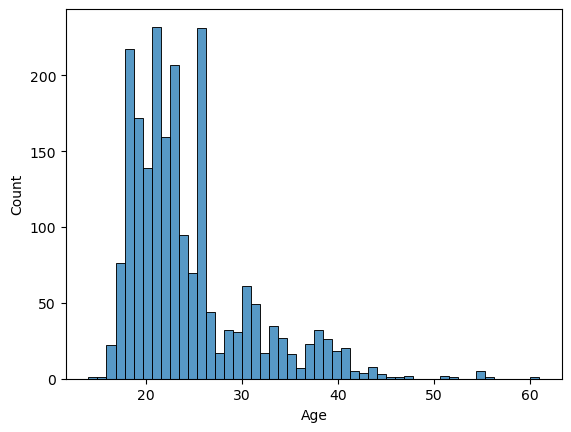

In [11]:
sns.histplot(data=df, x="Age")

<Axes: xlabel='Height', ylabel='Count'>

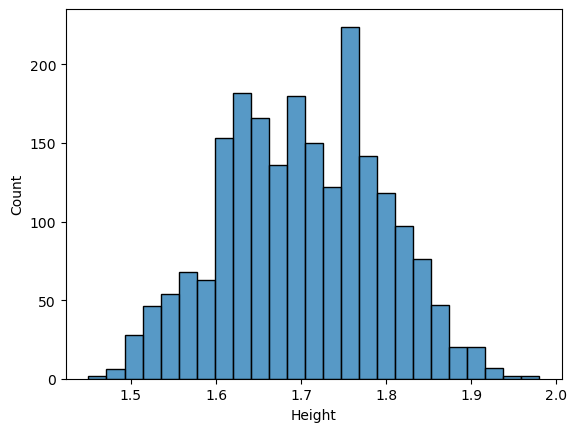

In [12]:
sns.histplot(data=df, x="Height")

<Axes: xlabel='Weight', ylabel='Count'>

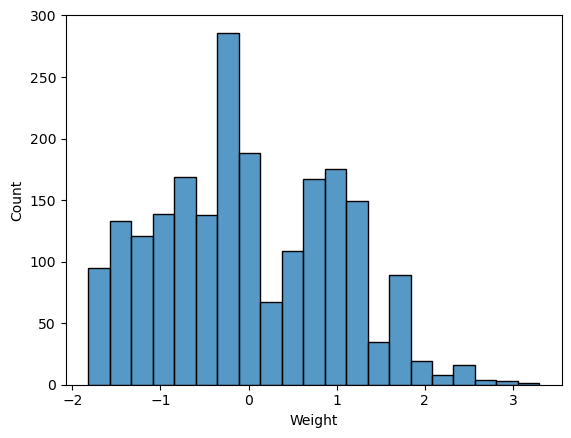

In [47]:
sns.histplot(data=df, x="Weight")

In [13]:
# Indicate the unique values in the numeric and categorical columns
num_col = ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']

# Convert numeric columns
for col in num_col:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

df[num_col] = df[num_col].fillna(0)

print("Updated data types for numeric columns:")
print(df[num_col].dtypes)

Updated data types for numeric columns:
Age       float64
Height    float64
Weight    float64
FCVC      float64
NCP       float64
CH2O      float64
FAF       float64
TUE       float64
dtype: object


In [14]:
# Indicate the unique values in the columns
columns = ['Gender', 'Age', 'Height', 'Weight', 'family_history_with_overweight', 'FAVC', 'FCVC', 'NCP','CAEC','SMOKE','CH2O','SCC',
           'FAF', 'TUE', 'CALC', 'MTRANS','NObeyesdad']

for i in columns:
    print(f'{i} unique values:' , df[i].unique())

Gender unique values: <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Age unique values: [21.       23.       27.       ... 22.524036 24.361936 23.664709]
Height unique values: [1.62     1.52     1.8      ... 1.752206 1.73945  1.738836]
Weight unique values: [ 64.        56.        77.       ... 133.689352 133.346641 133.472641]
family_history_with_overweight unique values: <StringArray>
['yes', 'no']
Length: 2, dtype: str
FAVC unique values: <StringArray>
['no', 'yes']
Length: 2, dtype: str
FCVC unique values: [2.       3.       1.       2.450218 2.880161 2.00876  2.596579 2.591439
 2.392665 1.123939 2.027574 2.658112 2.88626  2.714447 2.750715 1.4925
 2.205439 2.059138 2.310423 2.823179 2.052932 2.596364 2.767731 2.815157
 2.737762 2.568063 2.524428 2.971574 1.0816   1.270448 1.344854 2.959658
 2.725282 2.844607 2.44004  2.432302 2.592247 2.449267 2.929889 2.015258
 1.031149 1.592183 1.21498  1.522001 2.703436 2.362918 2.14084  2.5596
 2.336044 1.813234 2.724285 2.71897  1.133

In [15]:
# Clean target just in case there are missing values
df['NObeyesdad'] = df['NObeyesdad'].astype(str).str.strip()

# Target with 7 levels
target_map = {'Insufficient_Weight': 0, 'Normal_Weight': 1, 'Overweight_Level_I': 2, 'Overweight_Level_II': 3, 'Obesity_Type_I': 4,
              'Obesity_Type_II': 5, 'Obesity_Type_III': 6}

df['NObeyesdad'] = df['NObeyesdad'].replace(target_map)

# Binary map
df['Gender'] = df['Gender'].replace({'Female': 0, 'Male': 1})
df['family_history_with_overweight'] = df['family_history_with_overweight'].replace({'no': 0, 'yes': 1})
df['FAVC'] = df['FAVC'].replace({'no': 0, 'yes': 1})
df['CAEC'] = df['CAEC'].replace({'no': 0, 'Sometimes': 1, 'Frequently': 2, 'Always': 3})
df['SMOKE'] = df['SMOKE'].replace({'no': 0, 'yes': 1})
df['SCC'] = df['SCC'].replace({'no': 0, 'yes': 1})
df['CALC'] = df['CALC'].replace({'no': 0, 'Sometimes': 1, 'Frequently': 2, 'Always': 3})
df['MTRANS'] = df['MTRANS'].replace({'Public_Transportation': 0, 'Walking': 1, 'Automobile': 2, 'Motorbike': 3, 'Bike': 4})

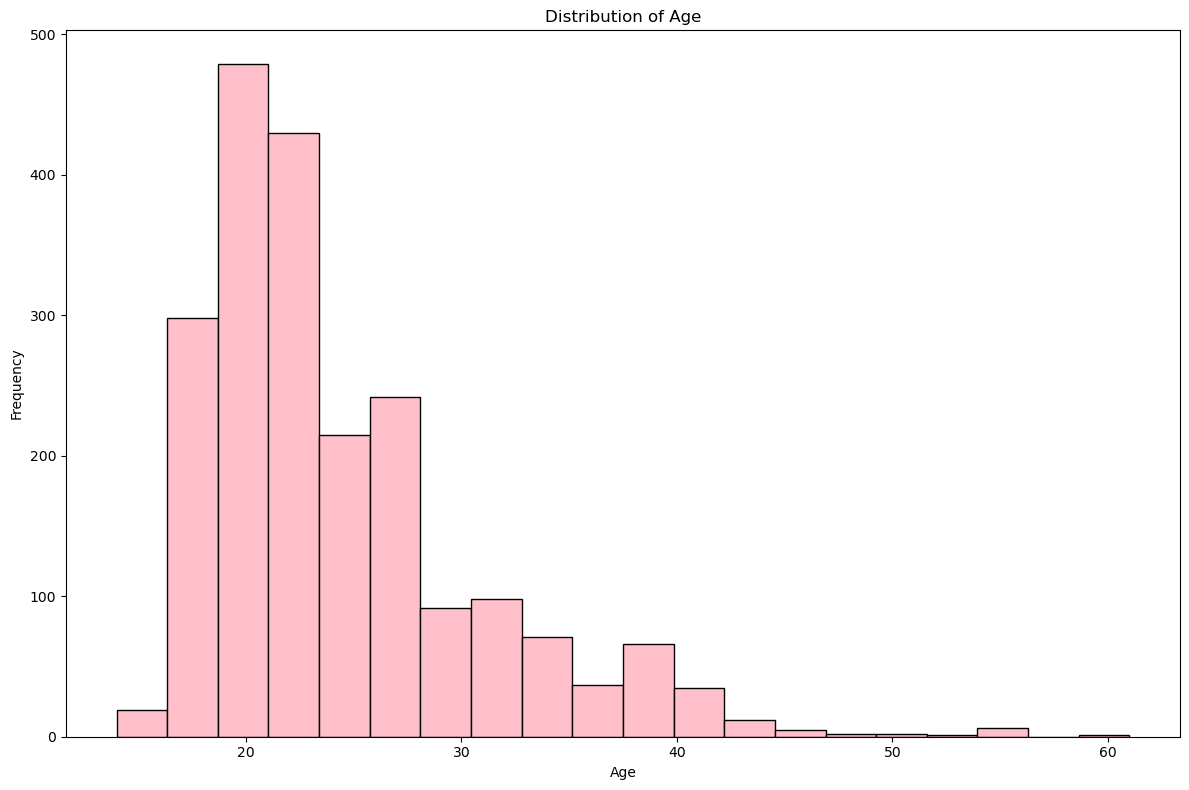

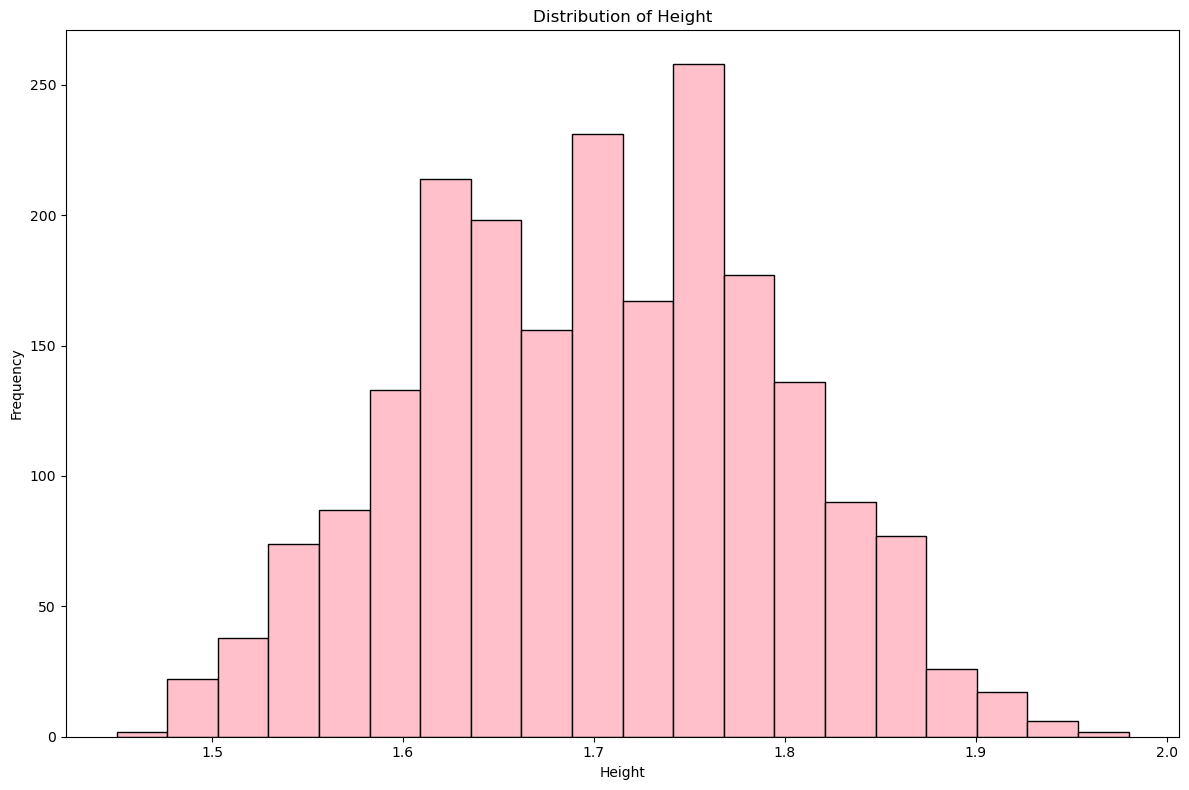

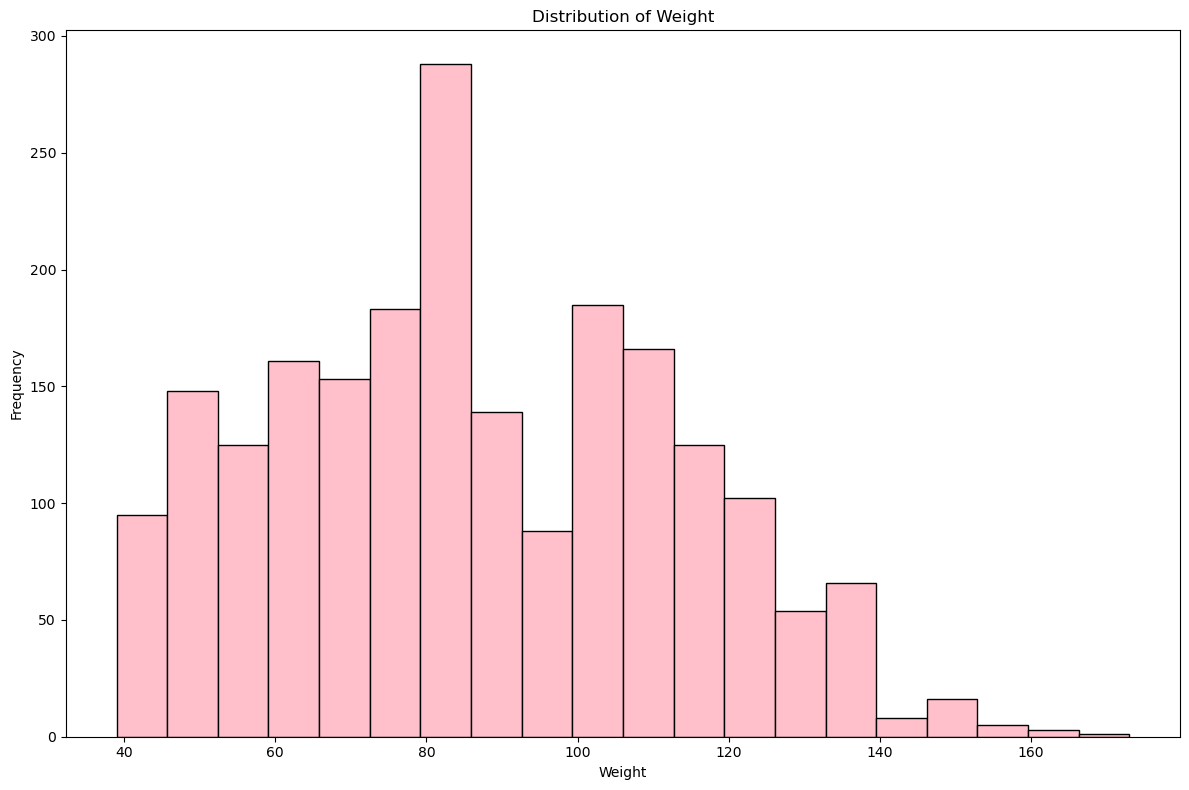

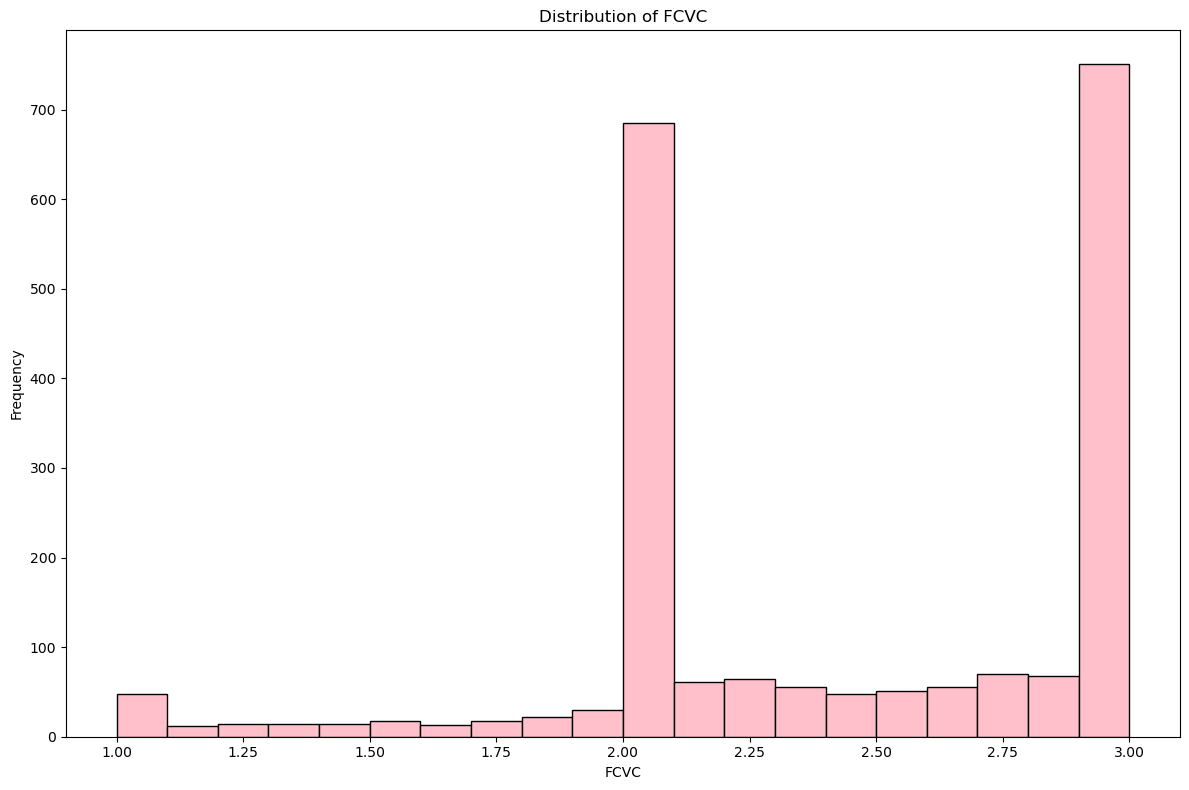

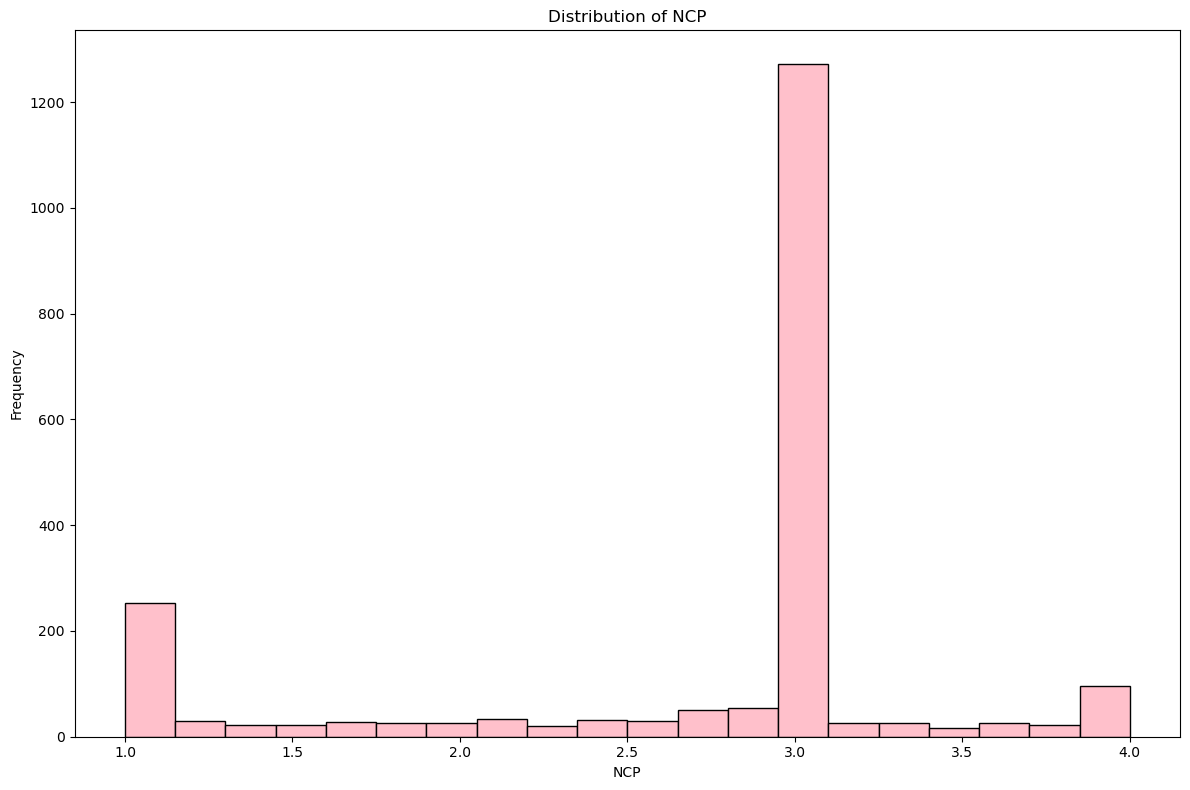

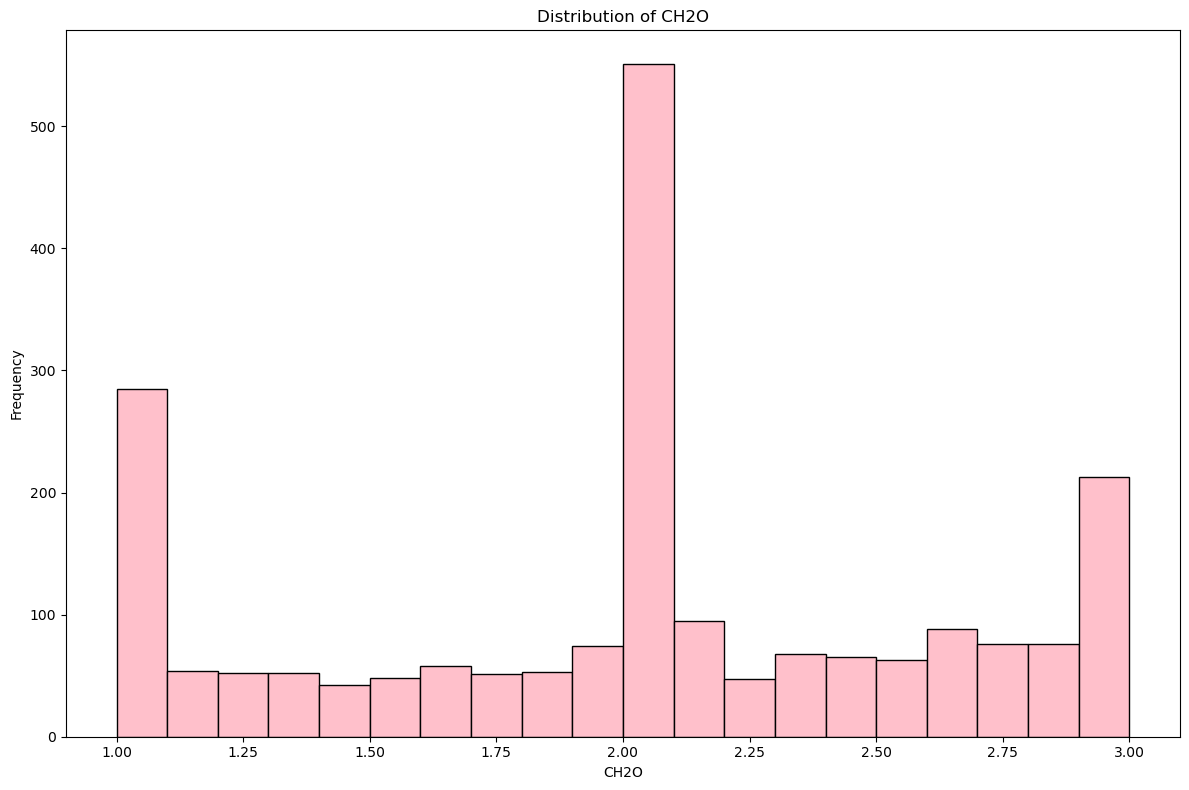

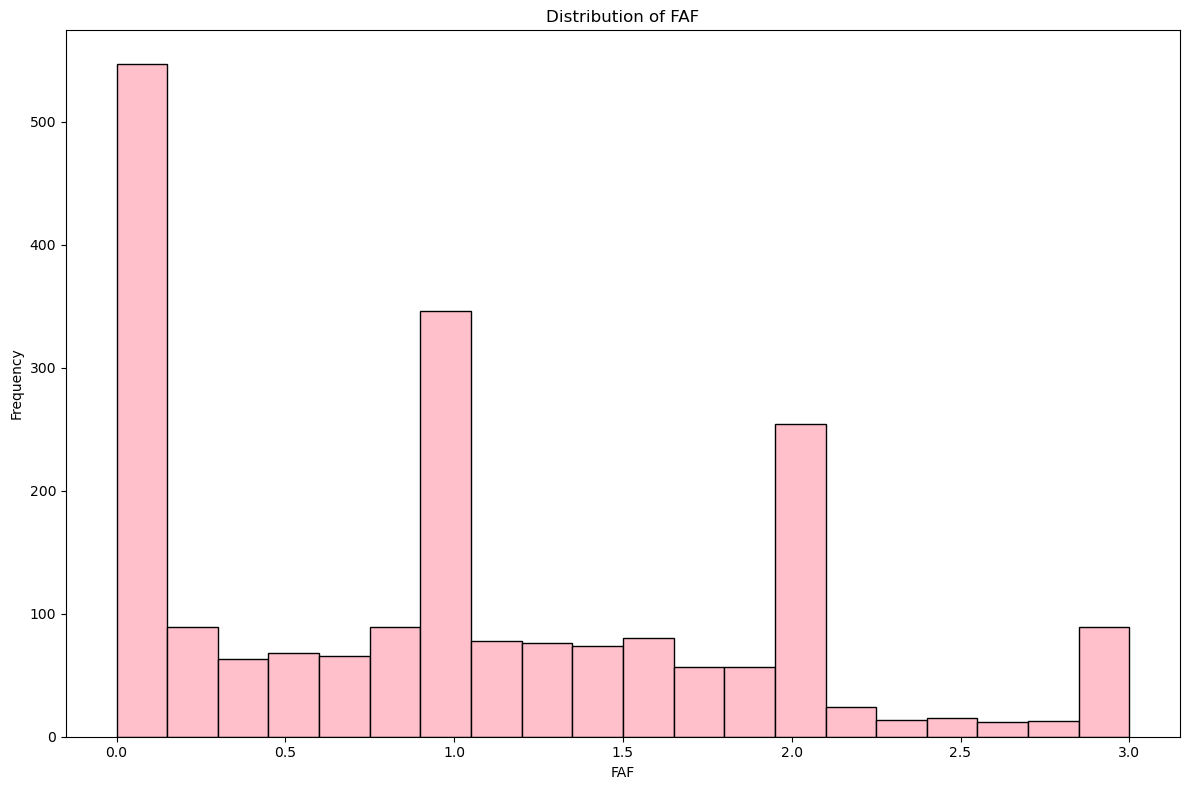

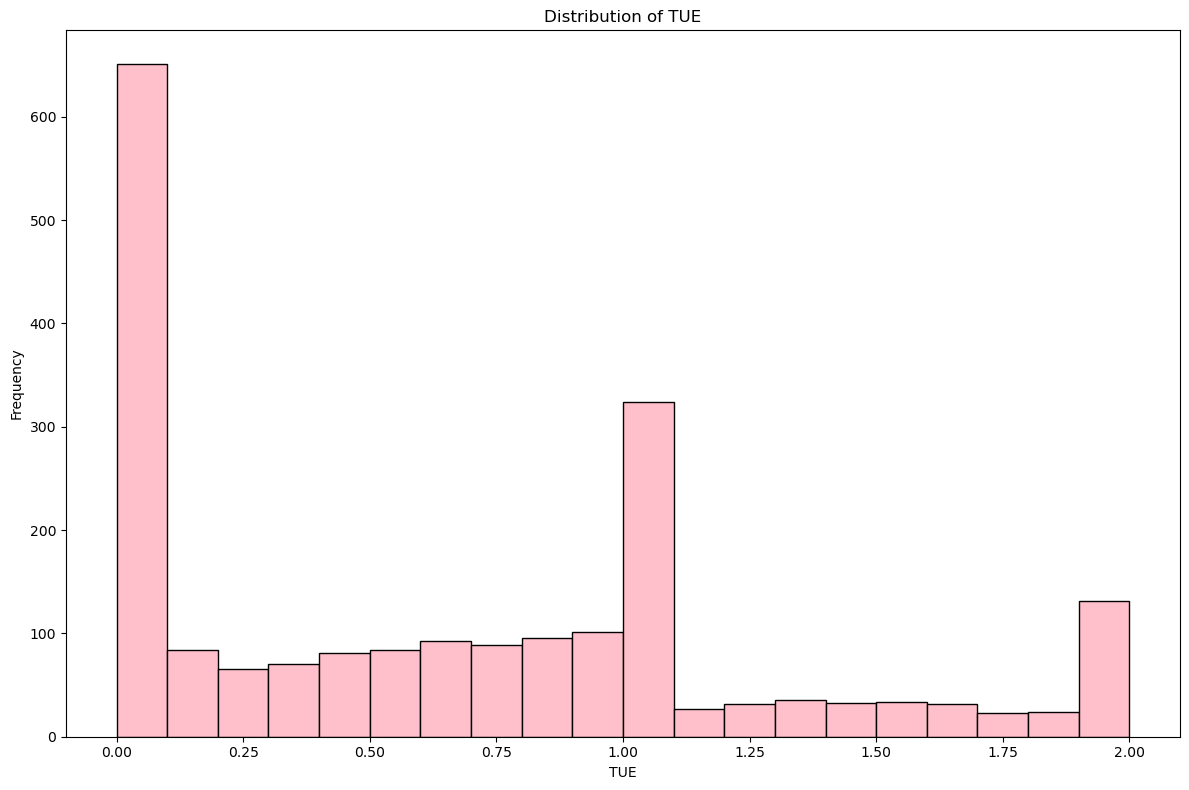

In [16]:
#Continuous columns
cont_col = ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']

df[cont_col] = df[cont_col].apply(pd.to_numeric, errors="coerce")

for i in cont_col:
    fig, ax = plt.subplots(figsize=(12, 8))
    
# Histogram graphic
    ax.hist(df[i].dropna(), bins=20, color='pink', edgecolor='black')
    ax.set_title(f'Distribution of {i}')
    ax.set_xlabel(i)
    ax.set_ylabel('Frequency')
    plt.tight_layout()
    plt.show()

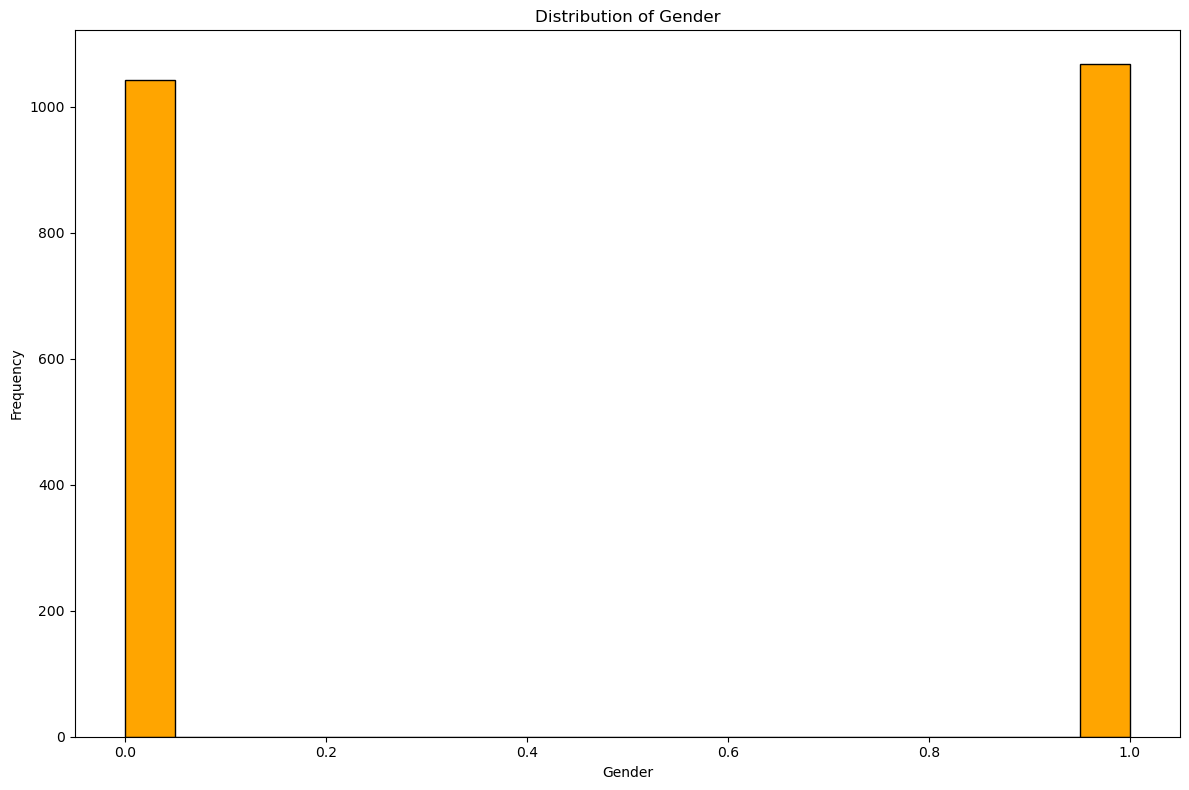

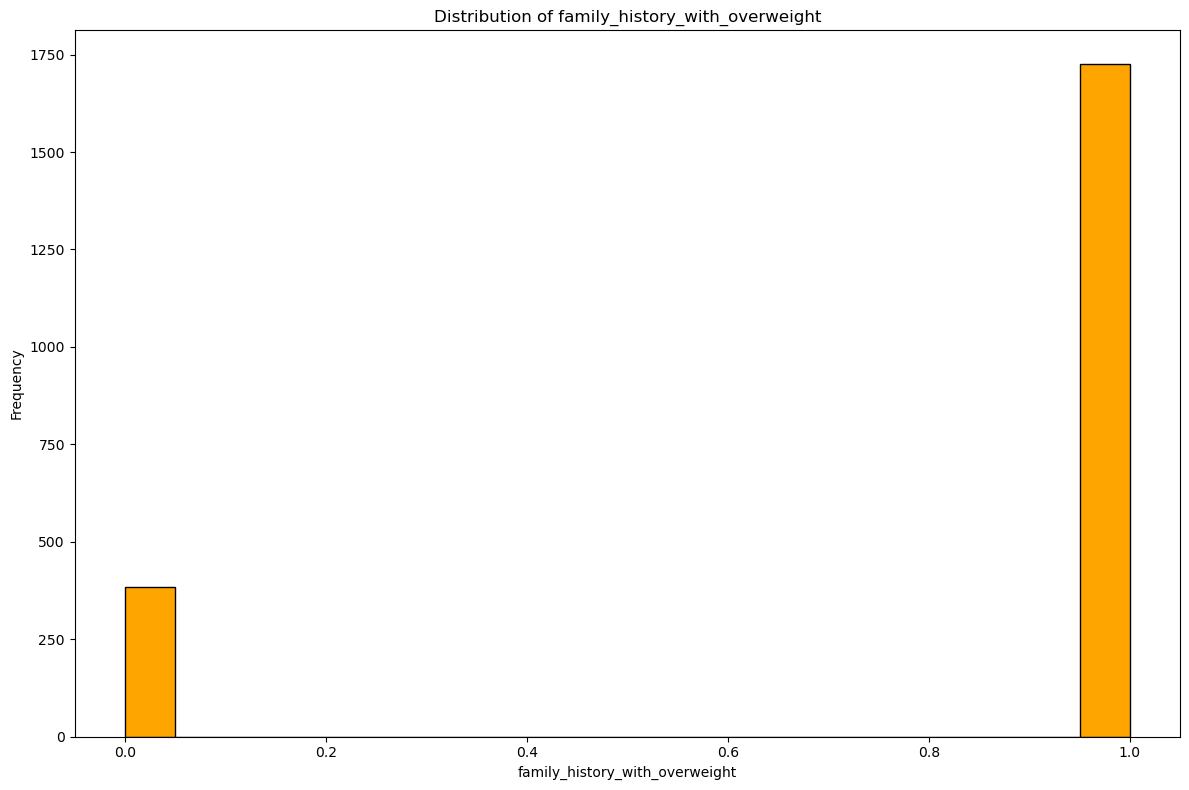

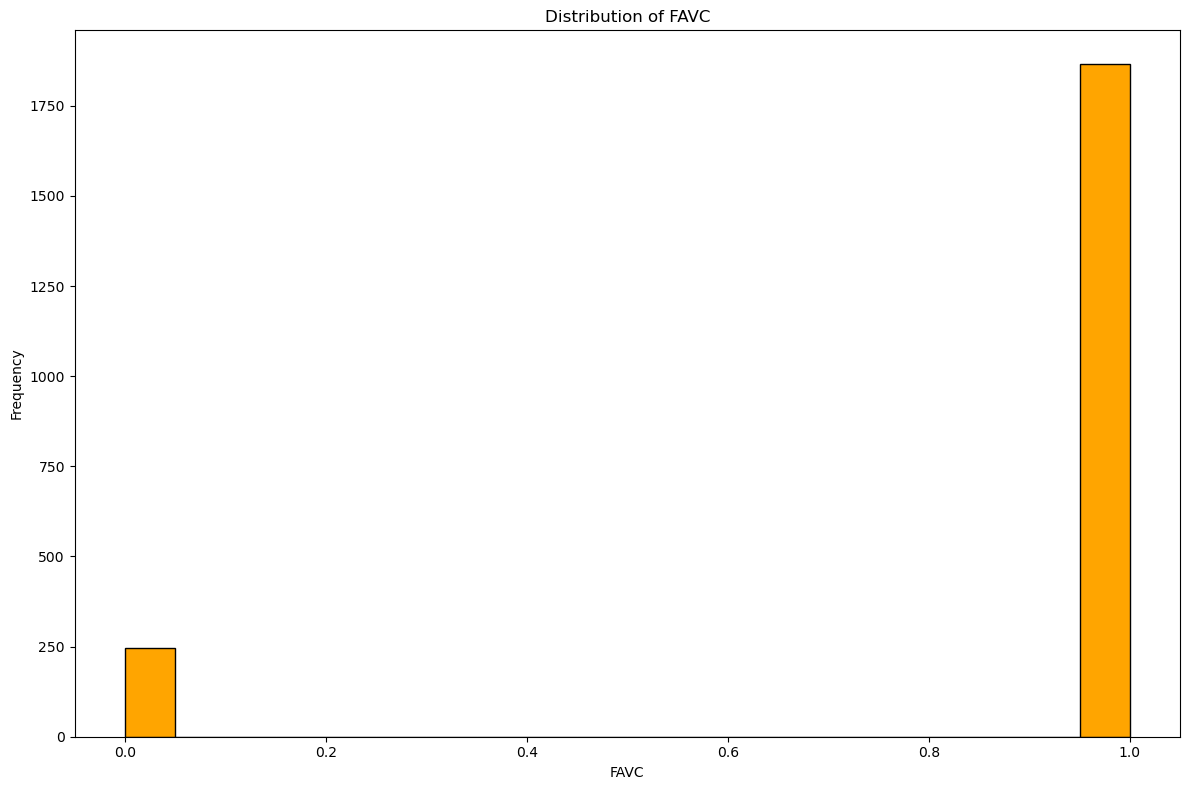

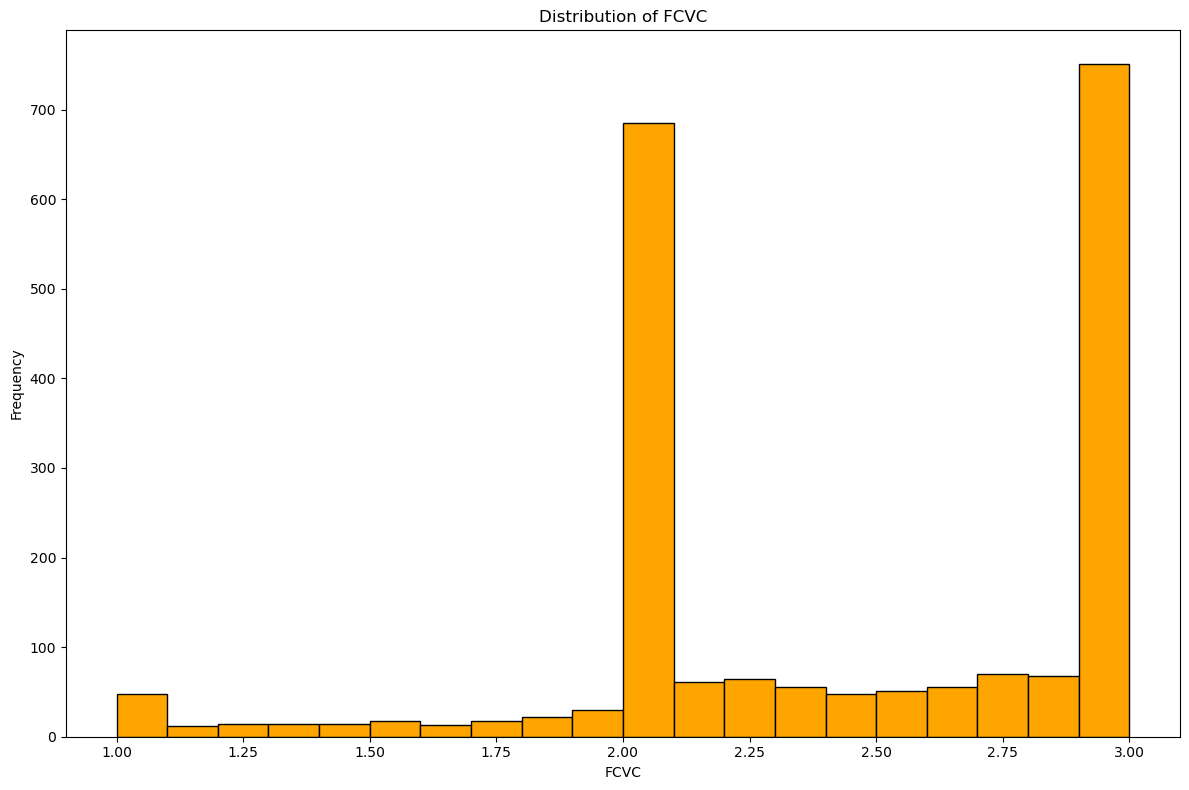

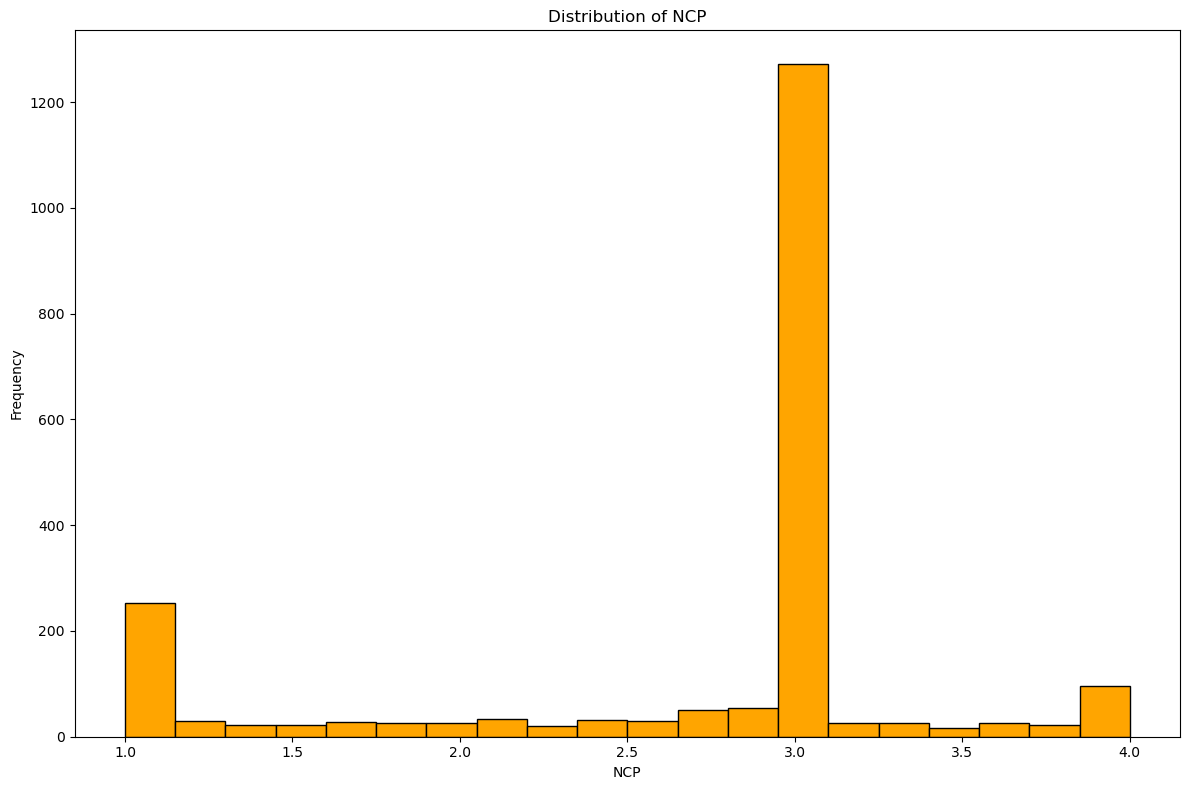

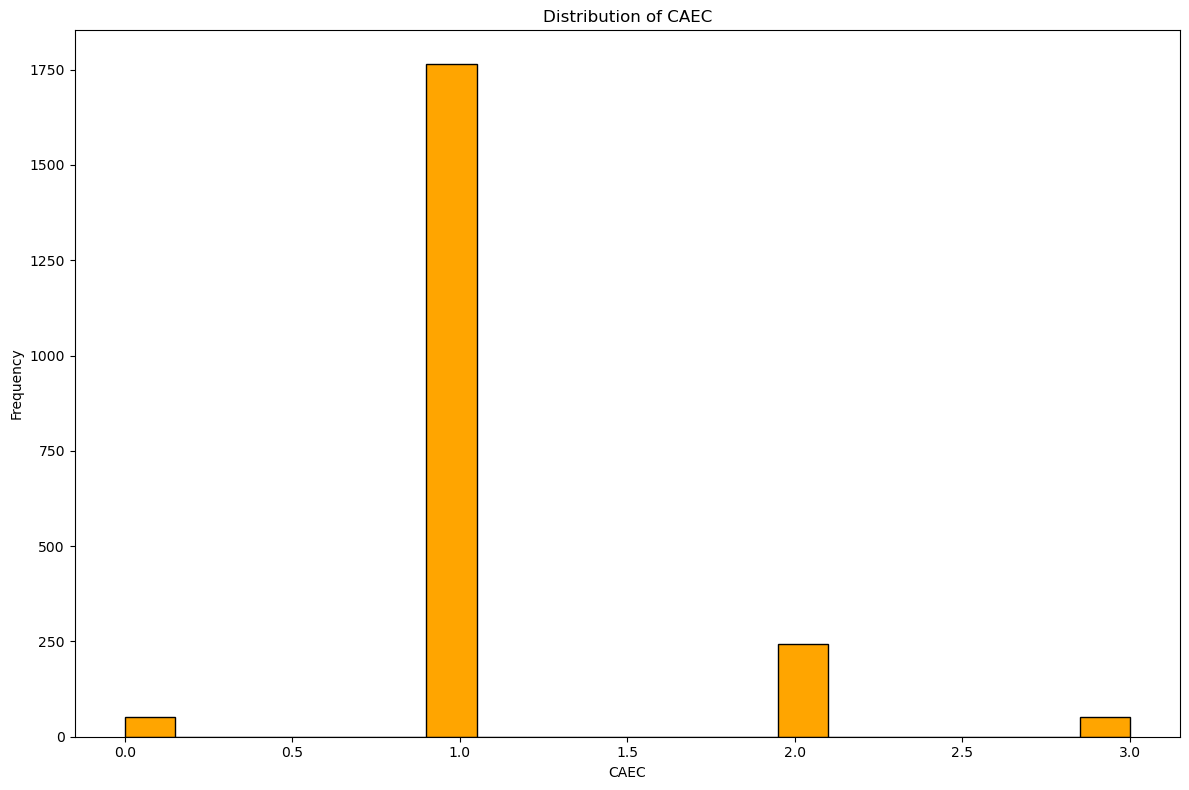

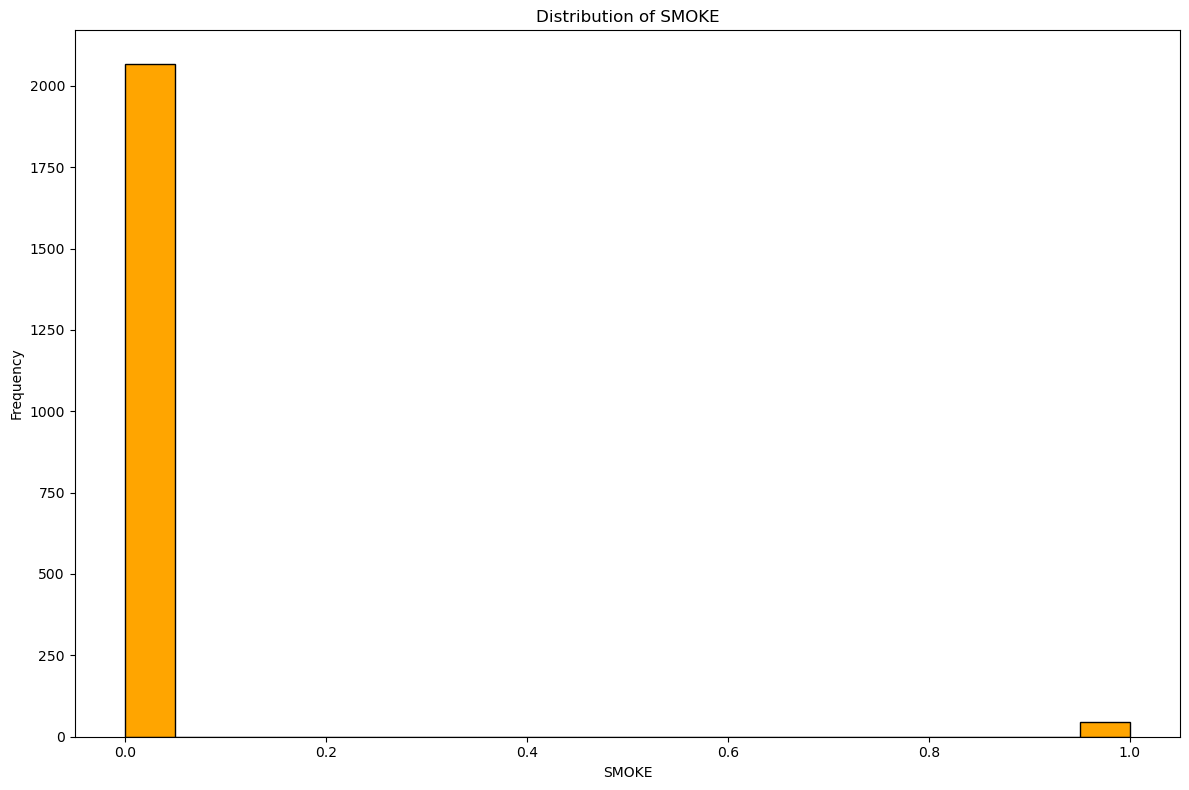

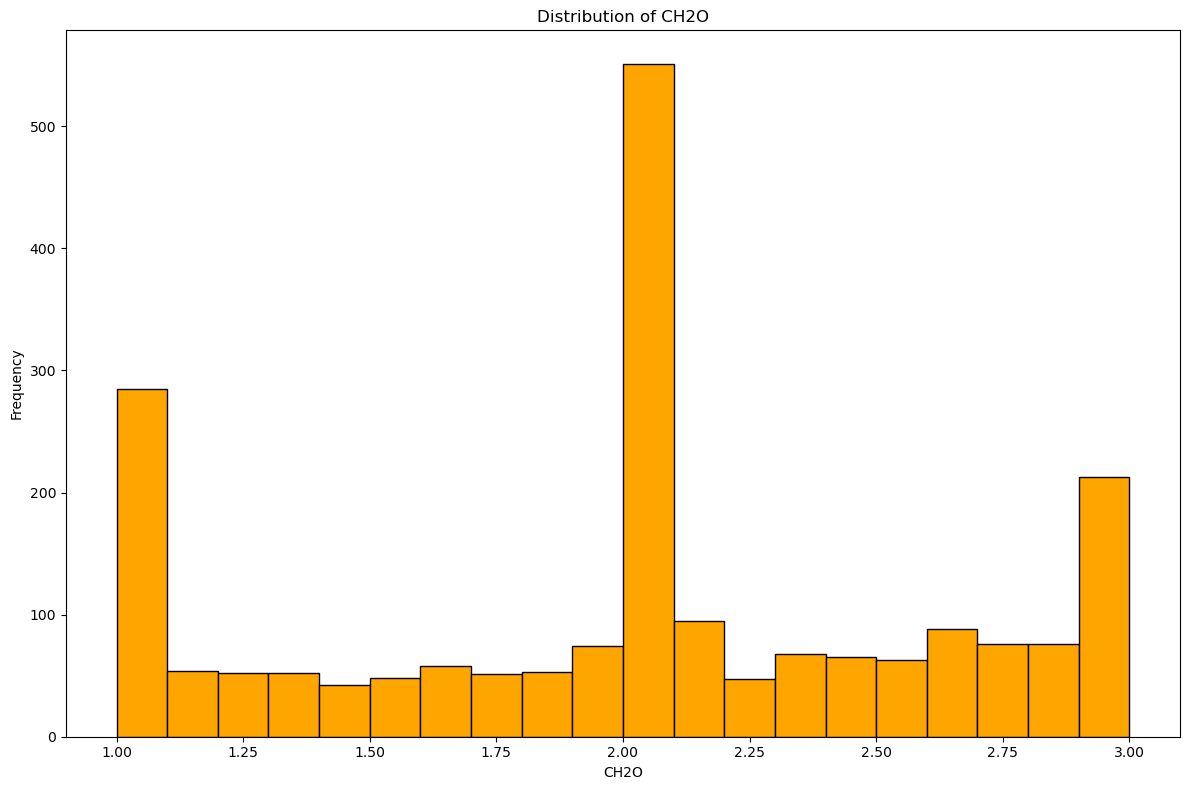

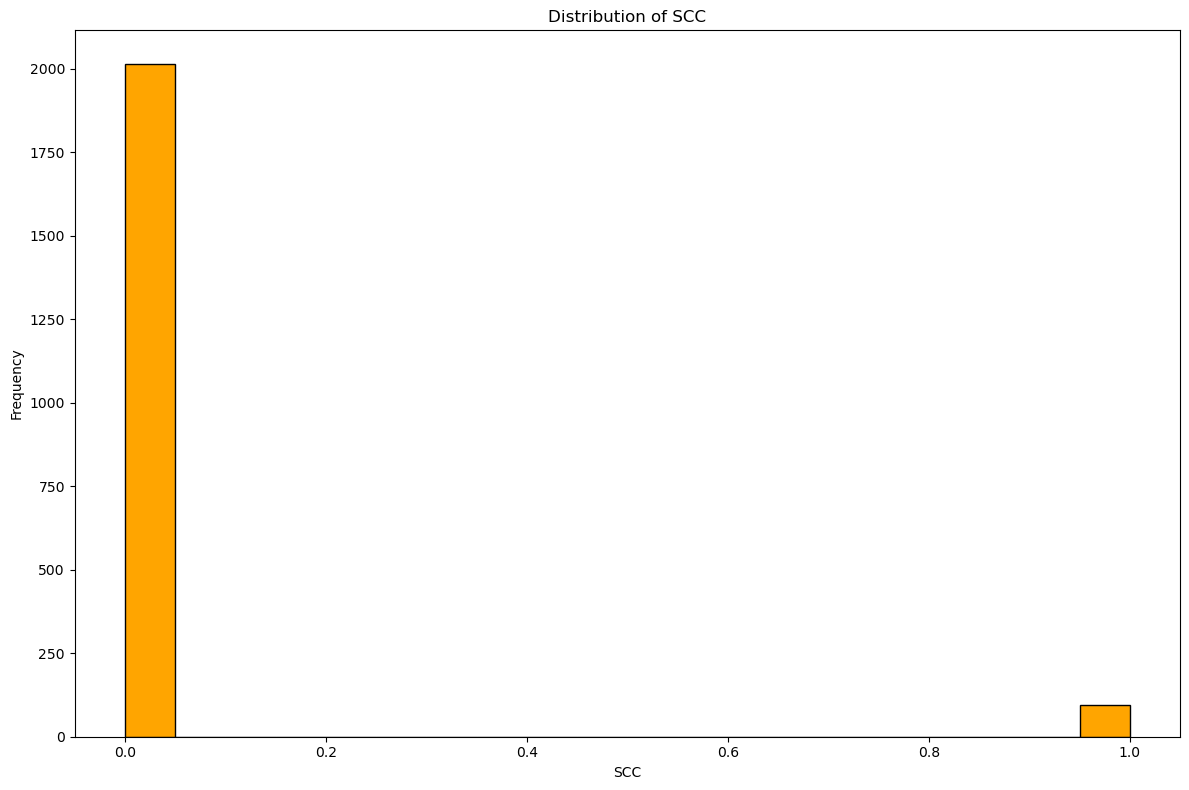

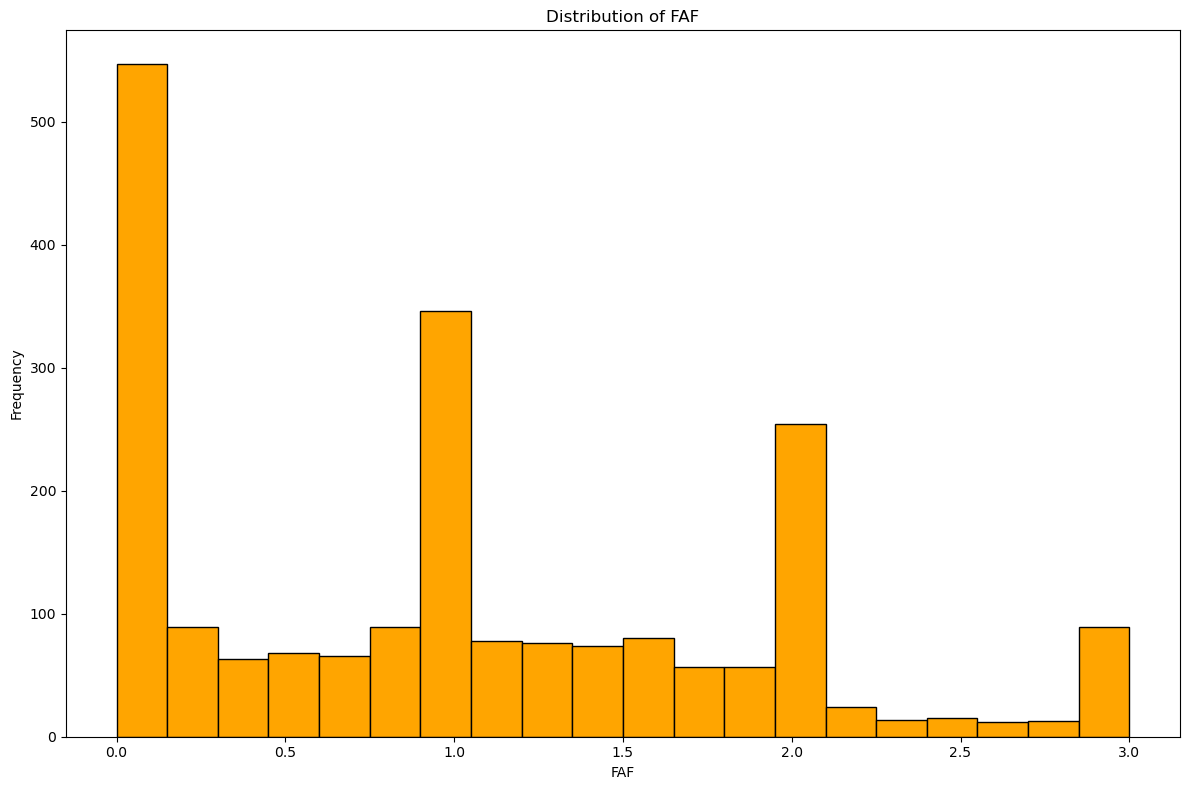

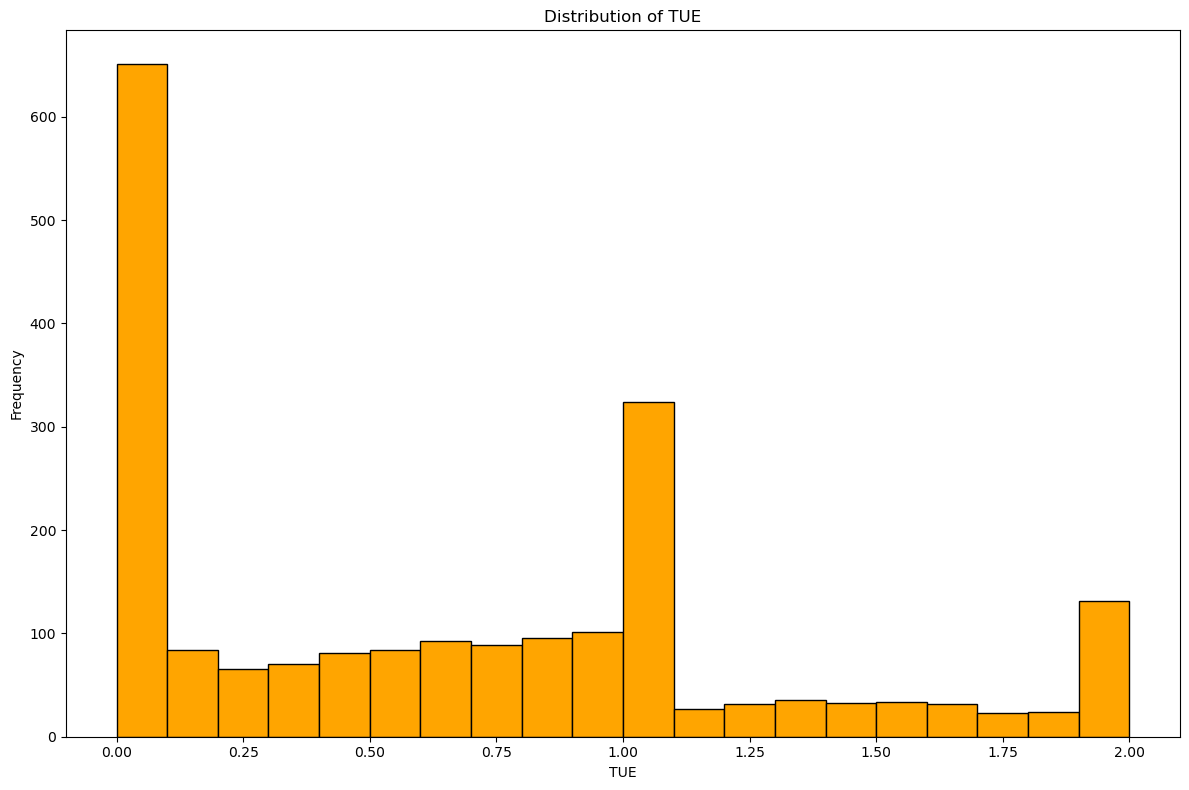

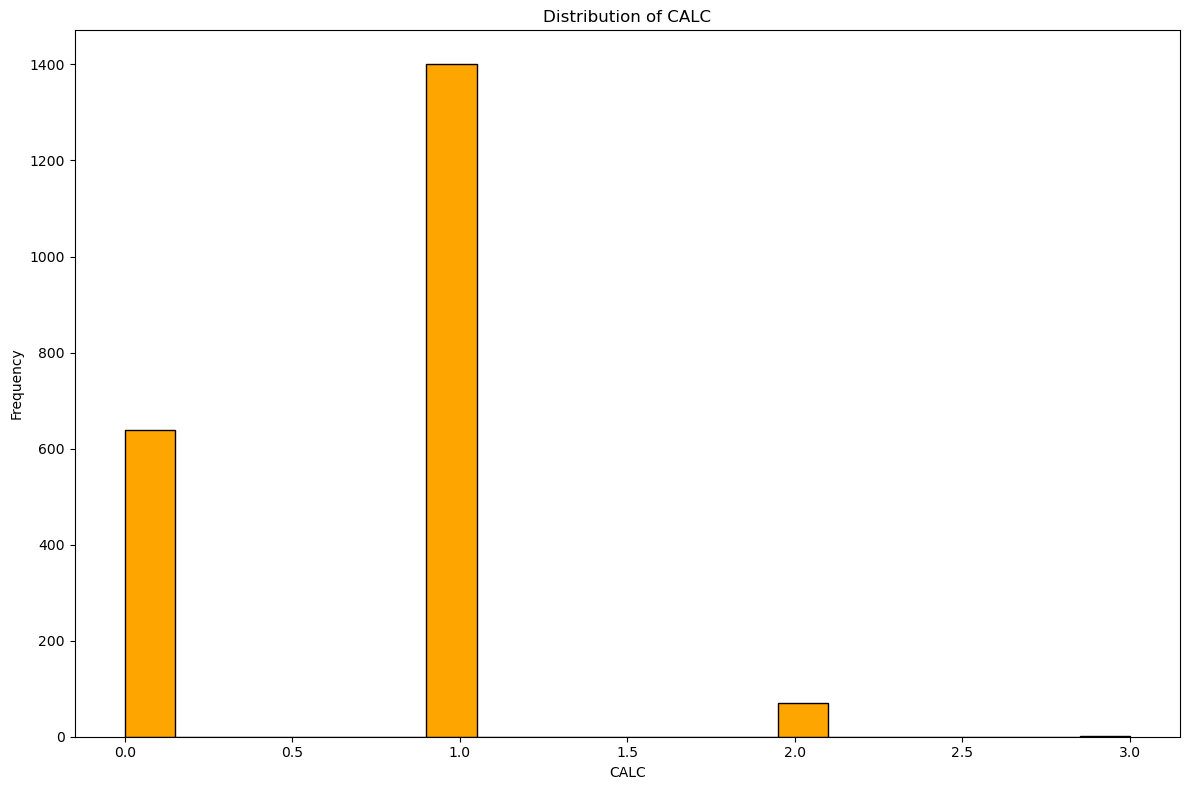

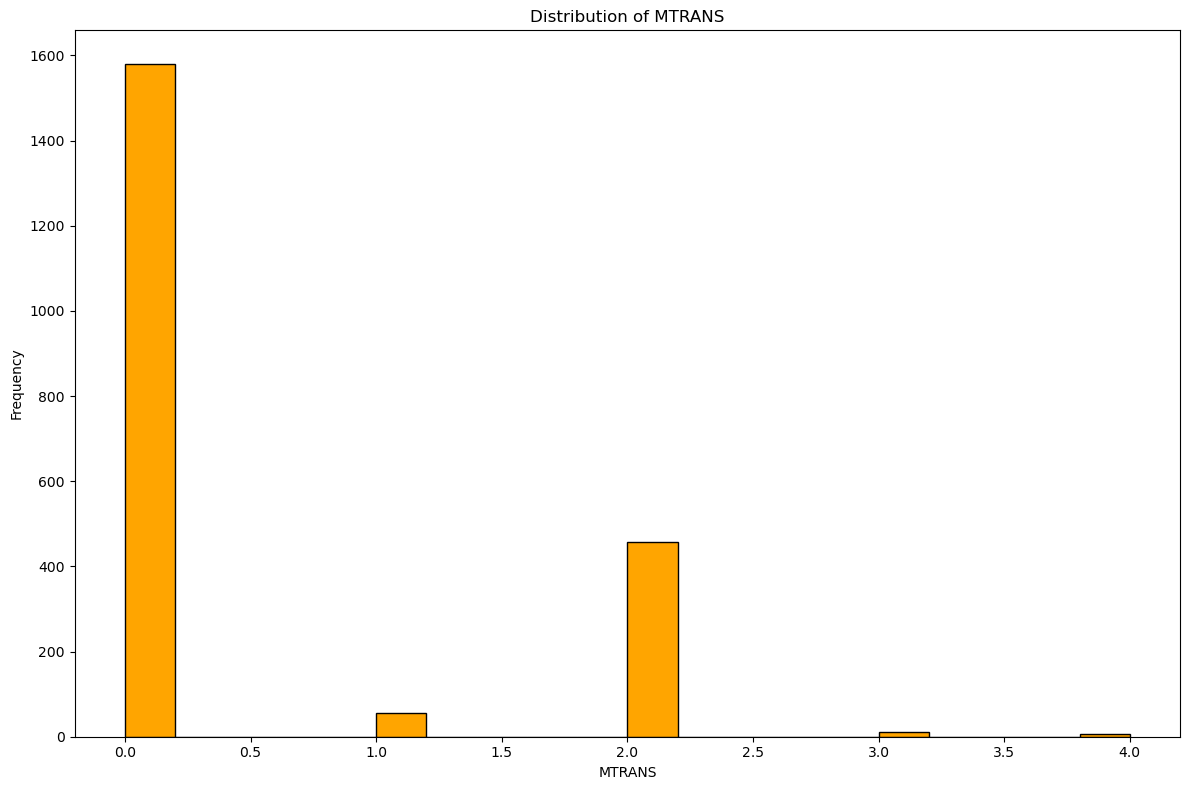

In [17]:
#Integer columns
integ_col = ['Gender', 'family_history_with_overweight', 'FAVC', 'FCVC', 'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE', 'CALC', 'MTRANS']

for i in integ_col:
    fig, ax = plt.subplots(figsize=(12, 8))
    
    # Histogram
    ax.hist(df[i].dropna(), bins=20, color='orange', edgecolor='black')
    ax.set_title(f'Distribution of {i}')
    ax.set_xlabel(i)
    ax.set_ylabel('Frequency')
    plt.tight_layout()
    plt.show()

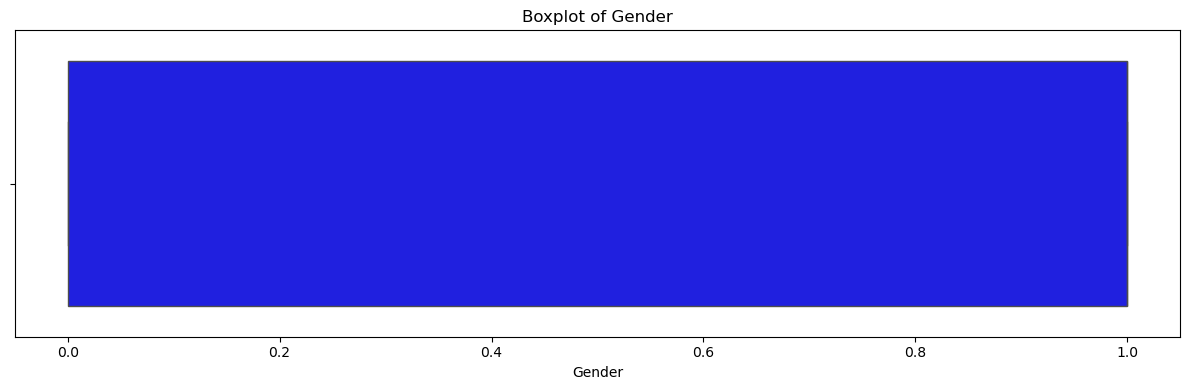

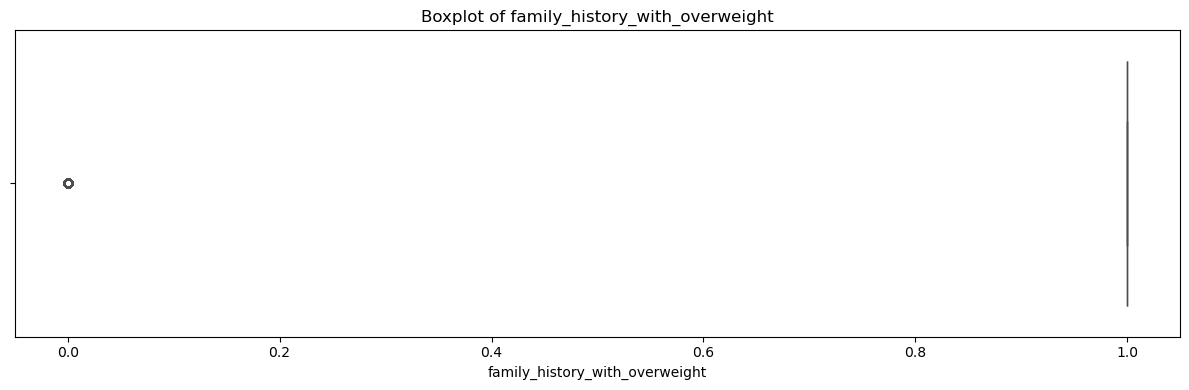

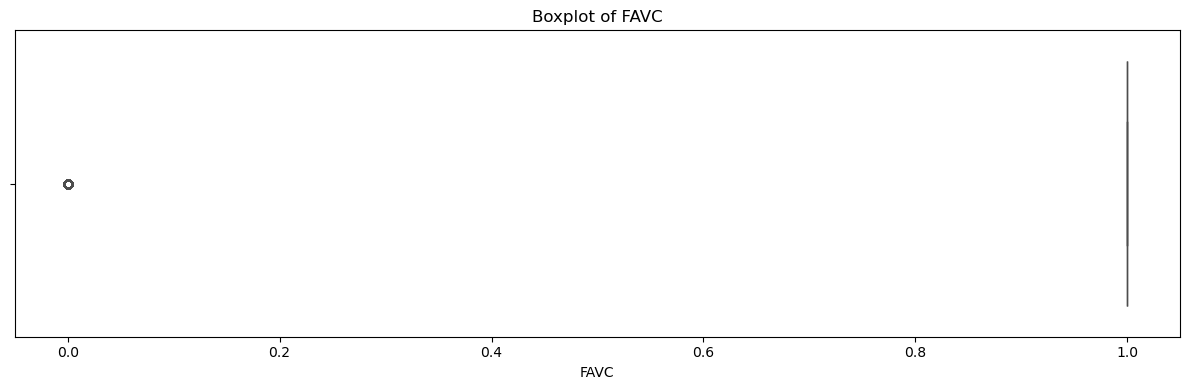

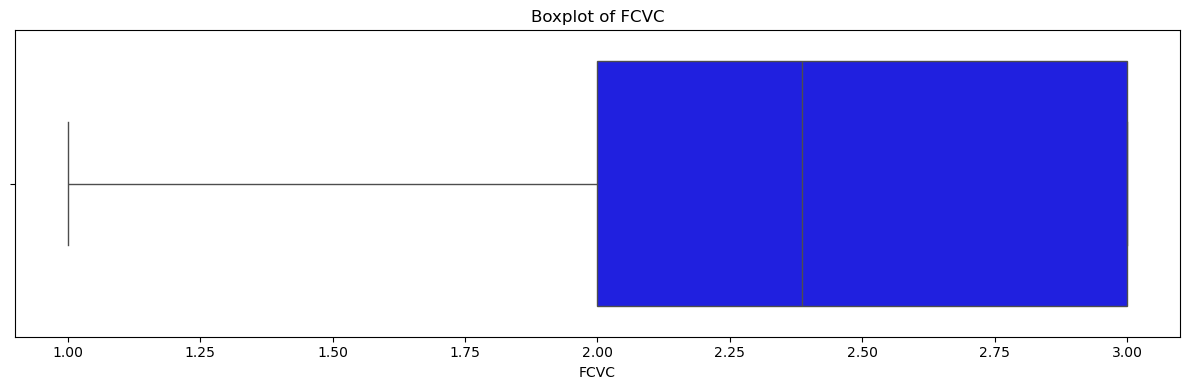

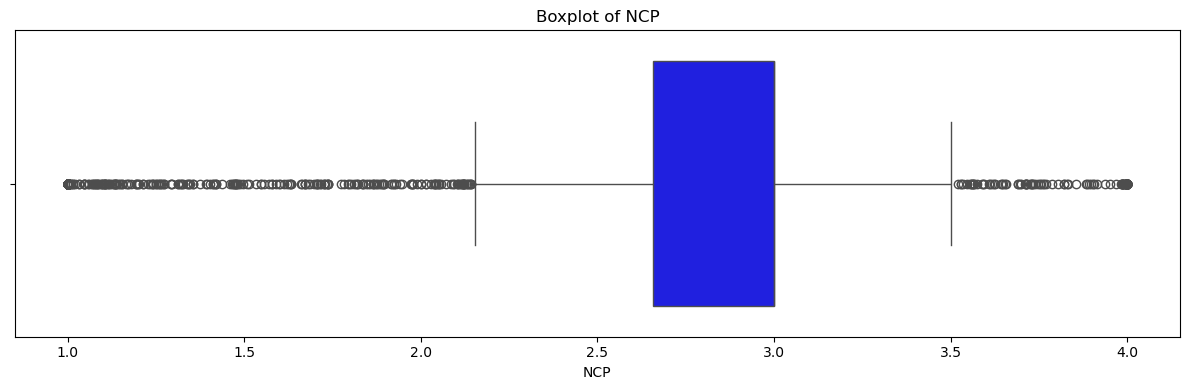

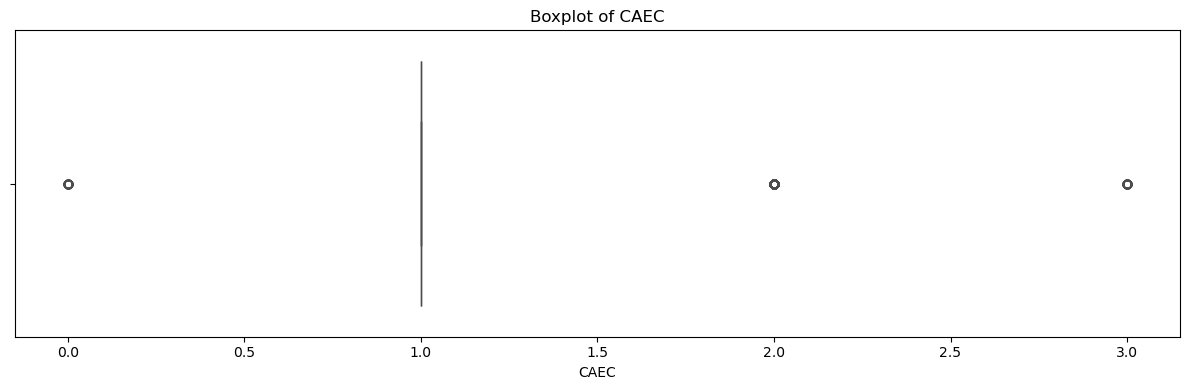

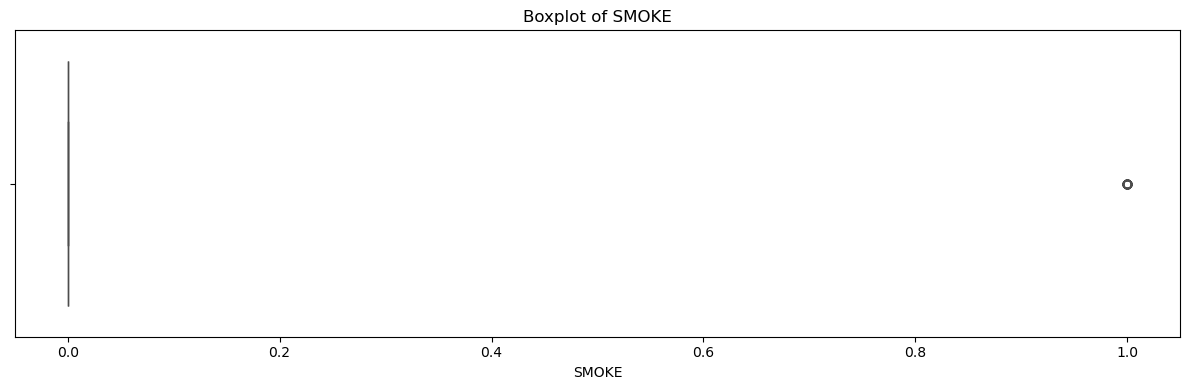

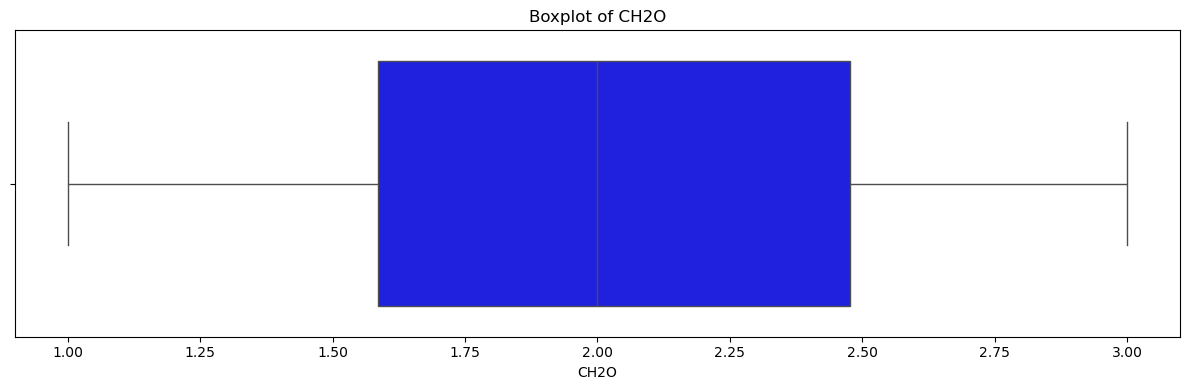

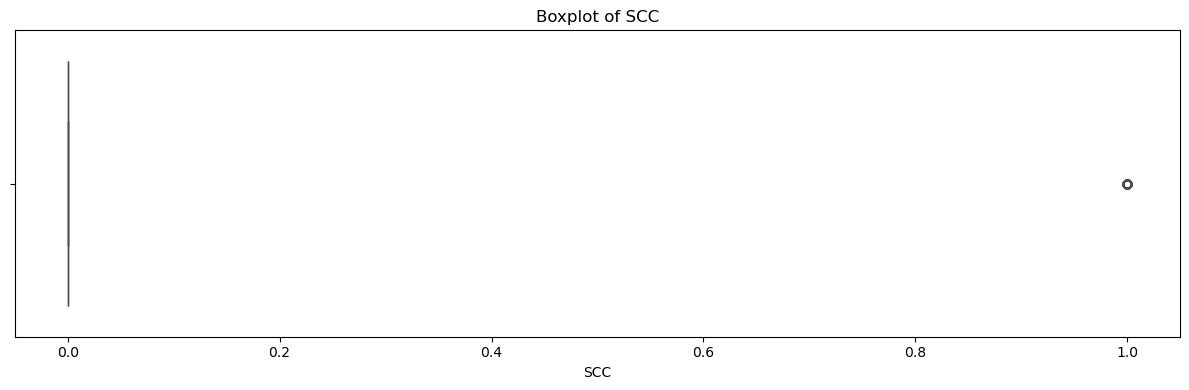

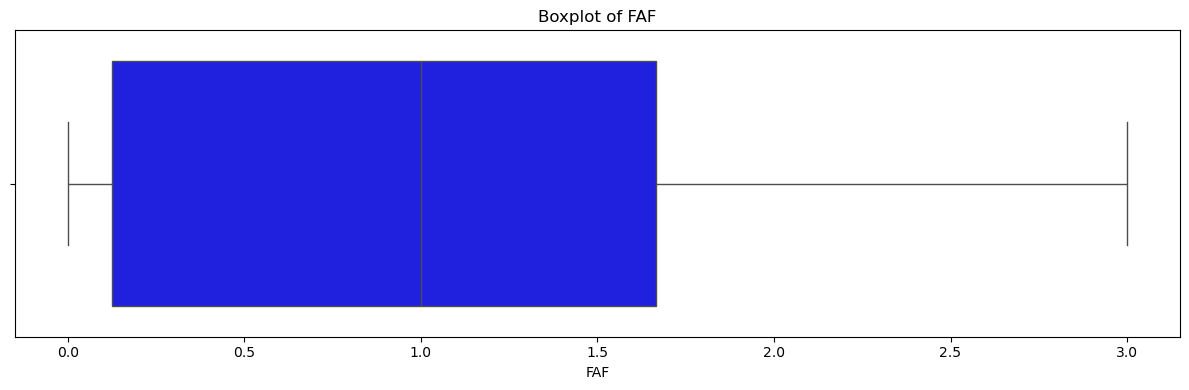

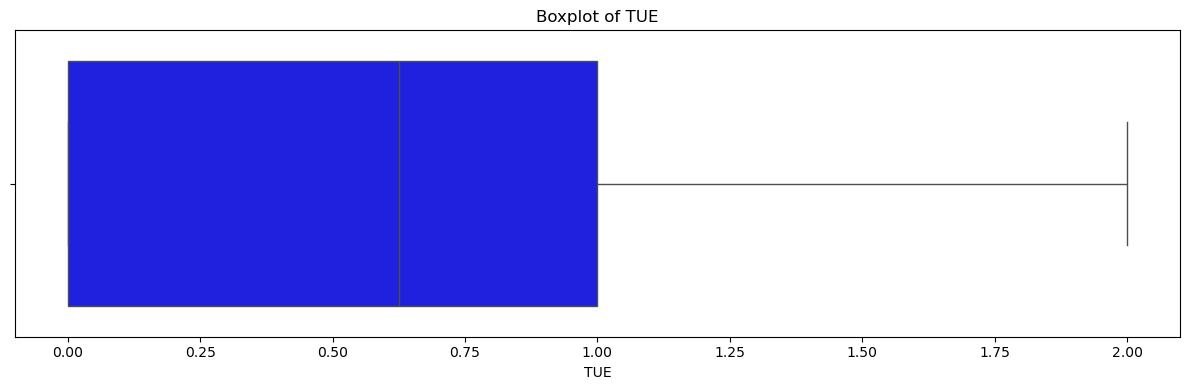

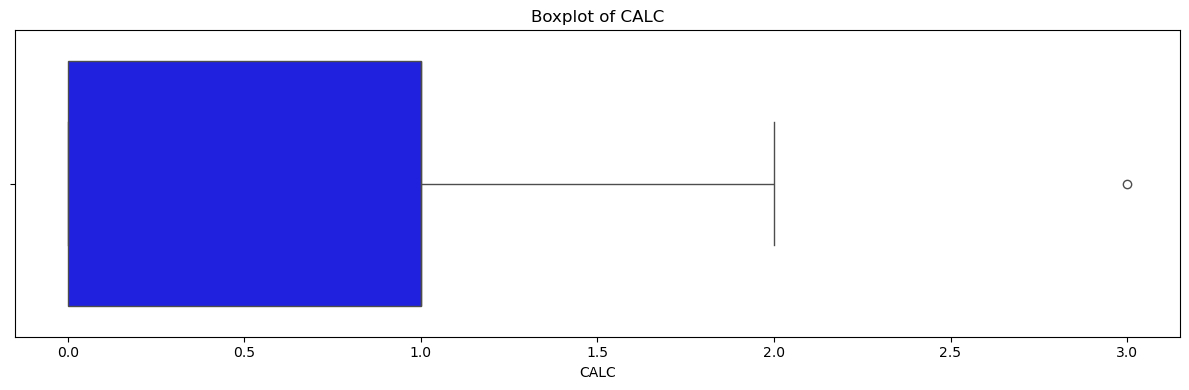

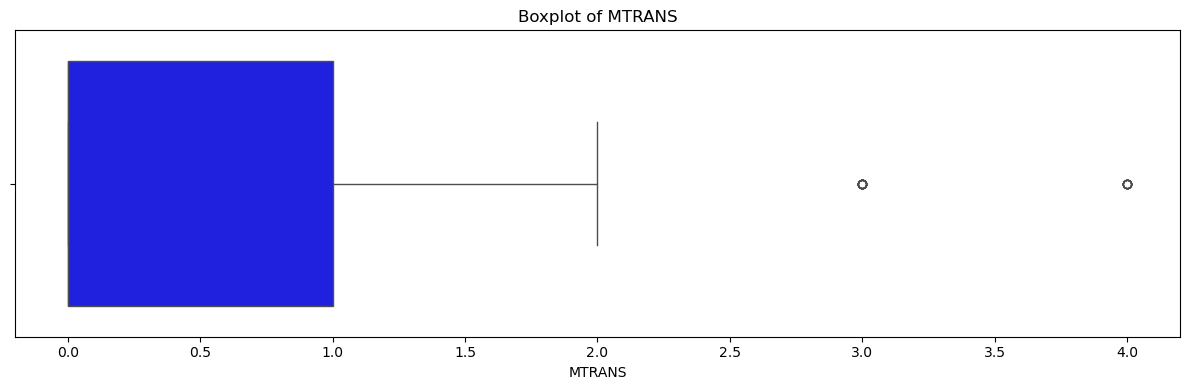

In [18]:
#Boxplot
for i in integ_col:
    plt.figure(figsize=(12, 4))
    
    # Histogram
    sns.boxplot(x=df[i].dropna(), color='blue')
    
    plt.title(f'Boxplot of {i}') 
    plt.xlabel(i)
    plt.tight_layout()
    plt.show()

<Axes: >

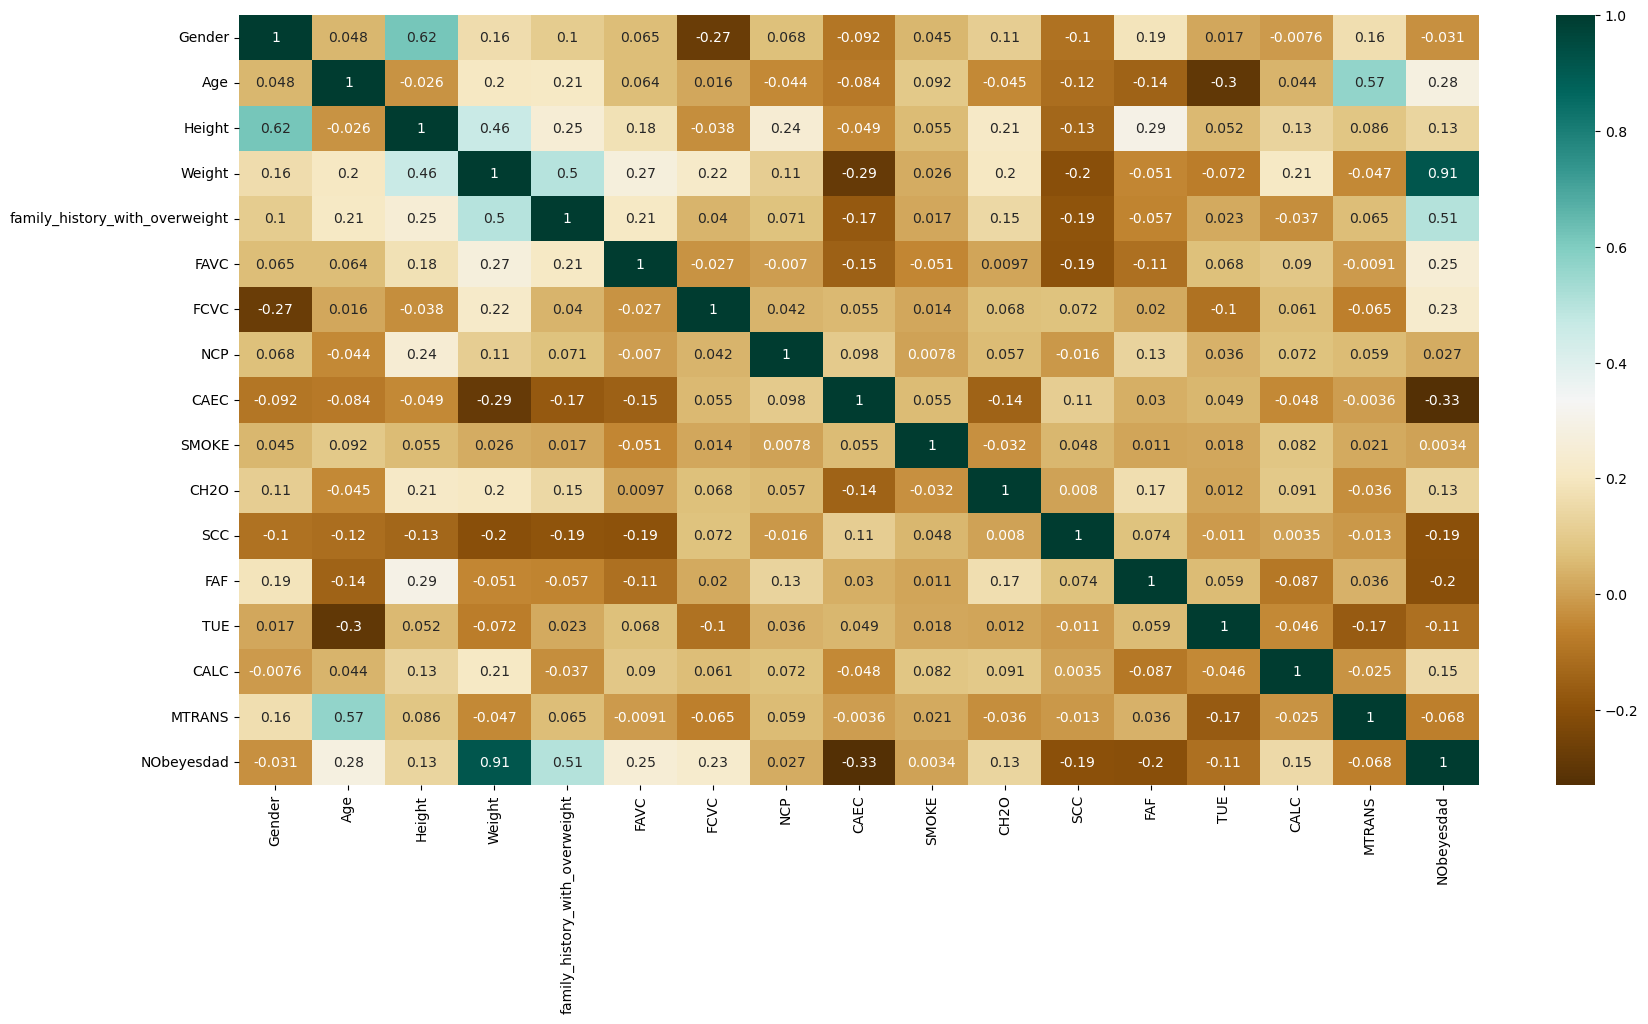

In [19]:
#Heatmap
df['NObeyesdad'] = df['NObeyesdad'].apply(pd.to_numeric, errors="coerce")

plt.figure(figsize=(20,10))
c= df.corr()
sns.heatmap(c,cmap="BrBG",annot=True)

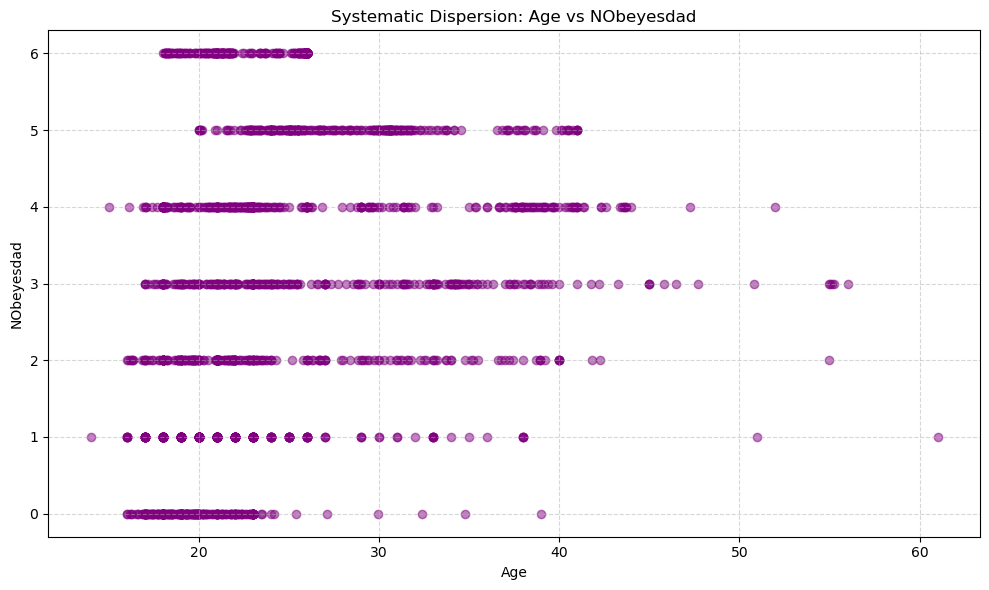

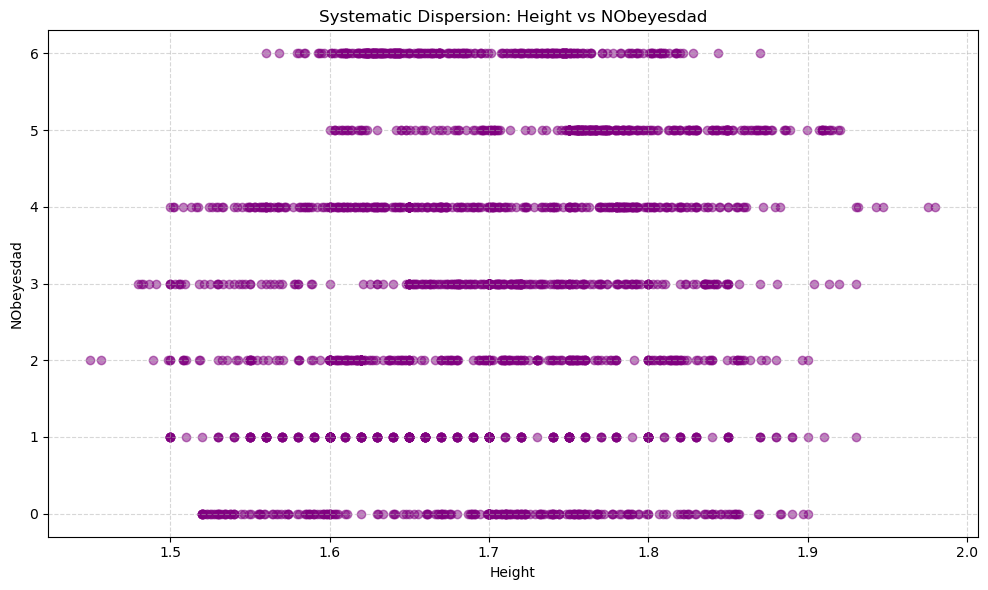

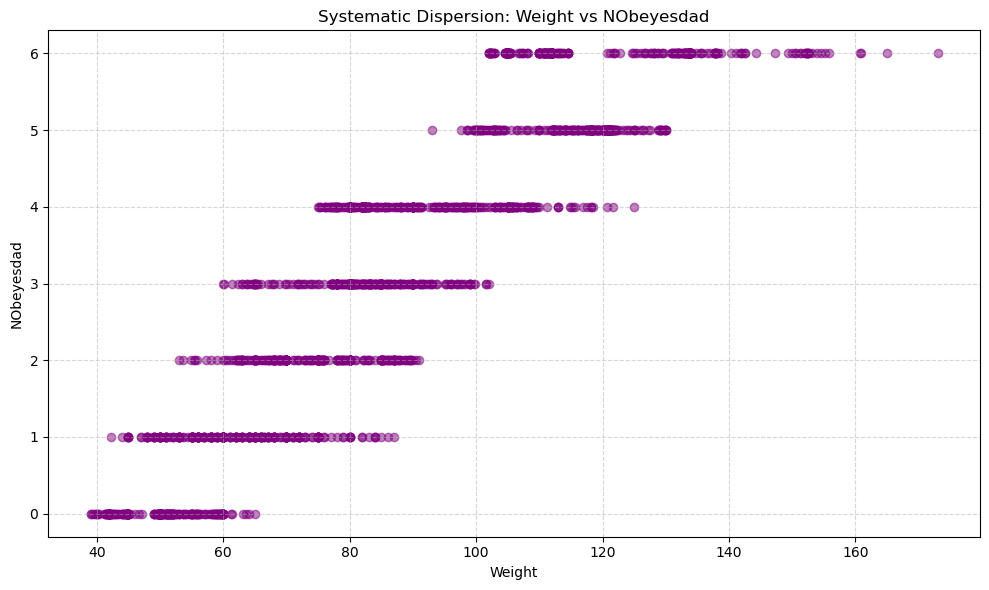

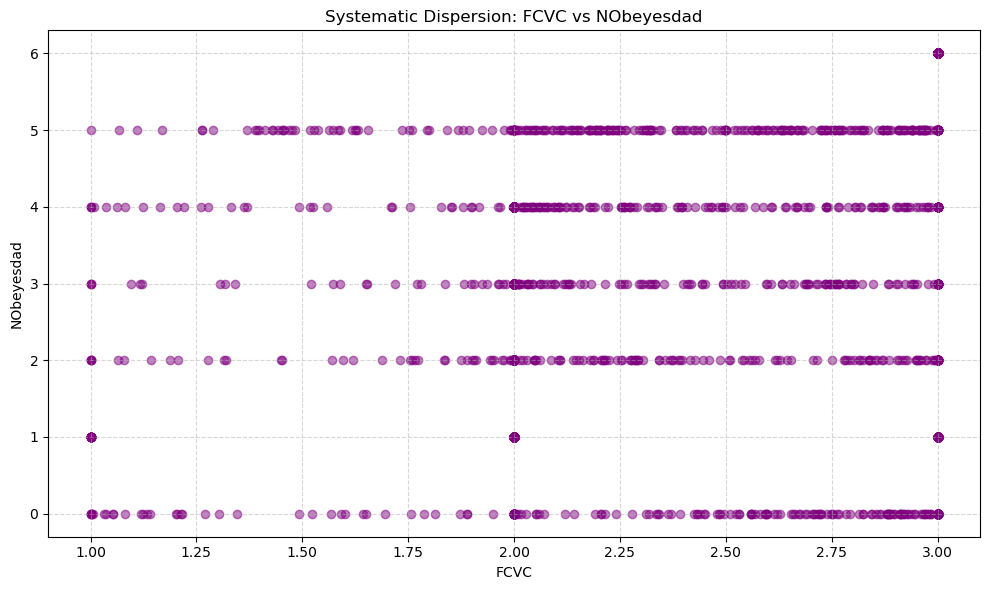

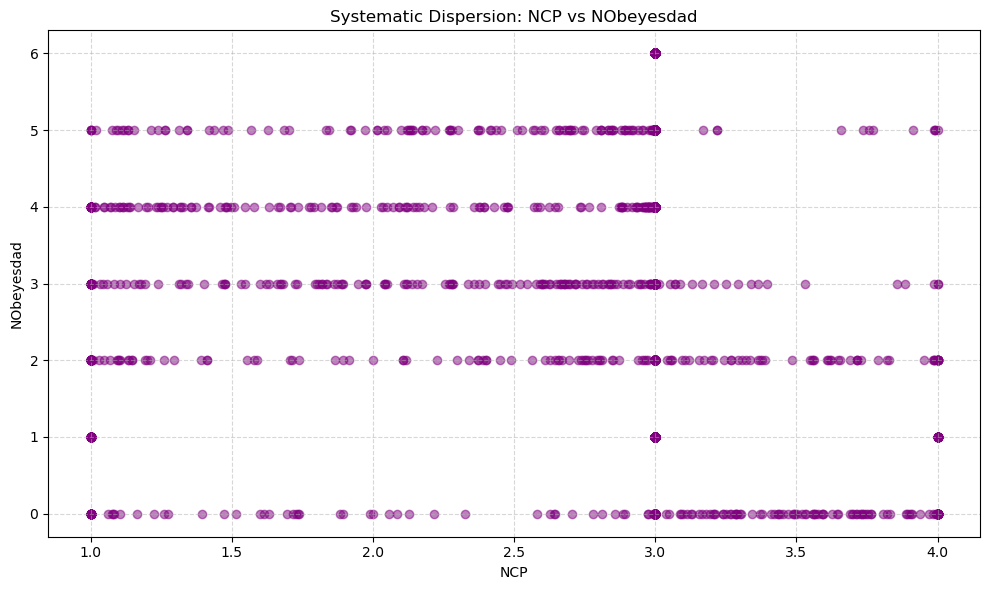

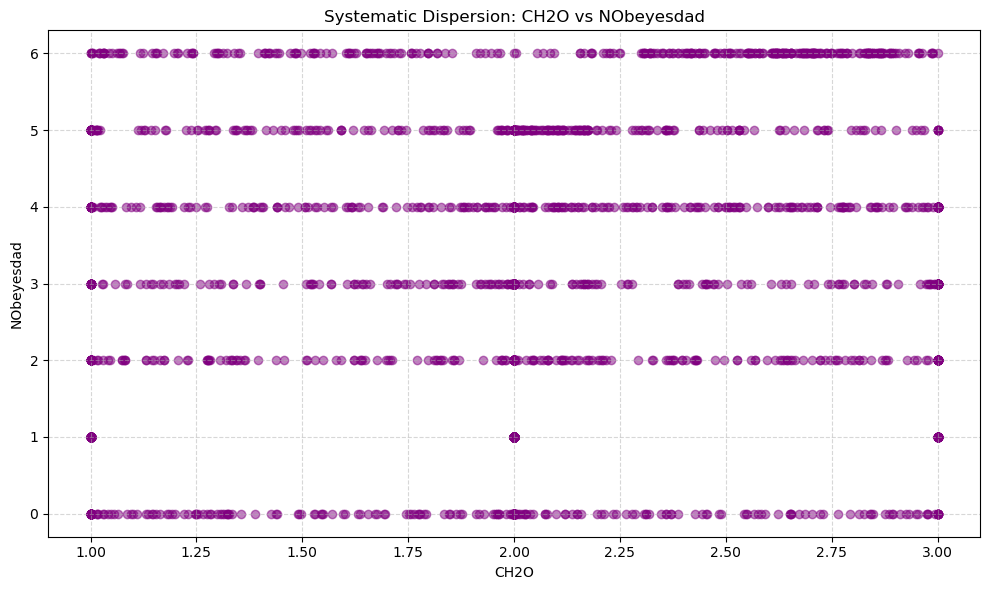

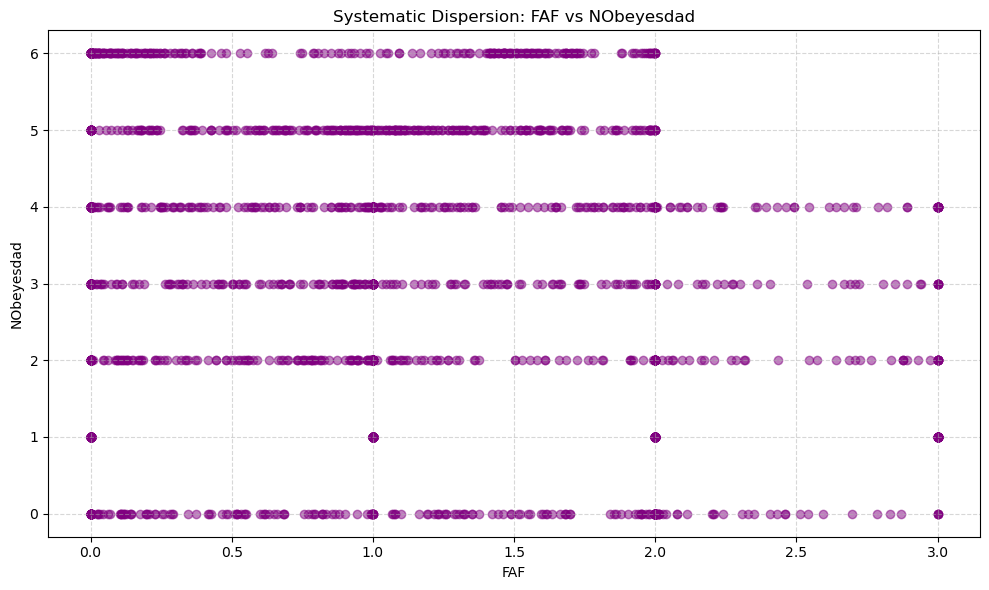

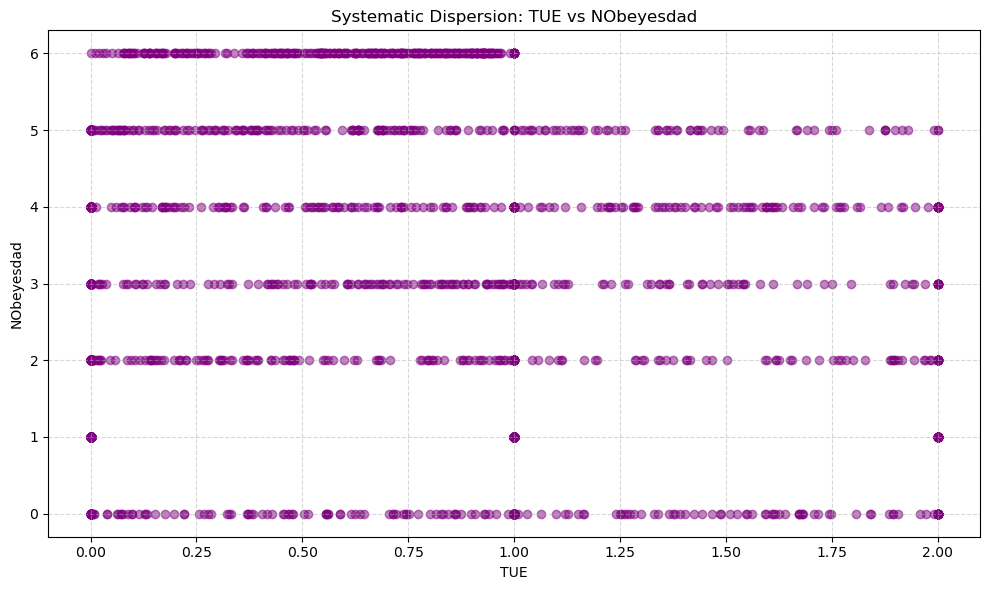

In [39]:
# Discrete and continuous columns
num_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Feature to use to compare graphically and delete so as not to compare the same variable
Target_variable = "NObeyesdad"
if Target_variable in num_cols:
    num_cols.remove(Target_variable)

# Numeric variable
for col in num_cols:
    fig, ax = plt.subplots(figsize=(10, 6))

    # Use alpha to different points
    ax.scatter(df[col], df[Target_variable], alpha=0.5, color="purple")
    ax.set_title(f"Systematic Dispersion: {col} vs {Target_variable}")
    ax.set_xlabel(col)
    ax.set_ylabel(Target_variable)
    ax.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

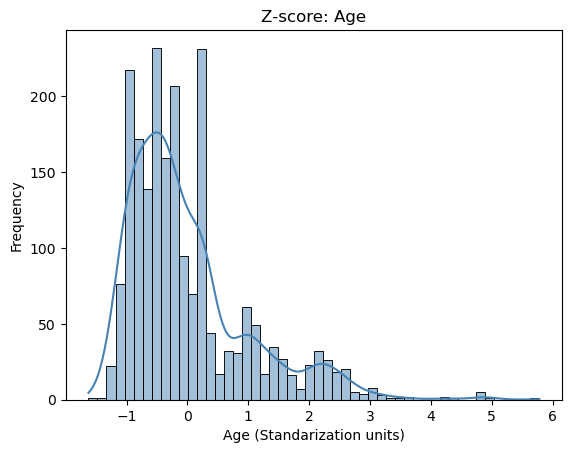

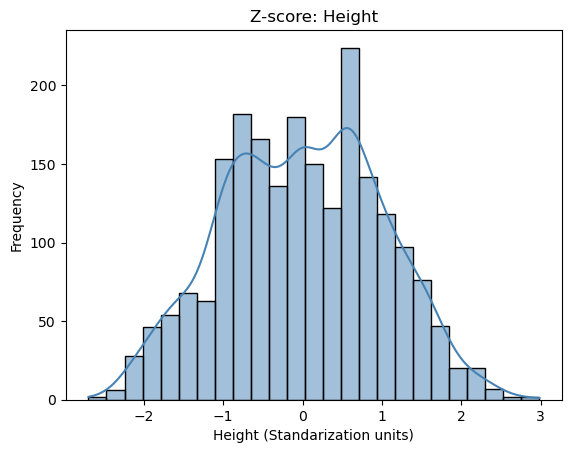

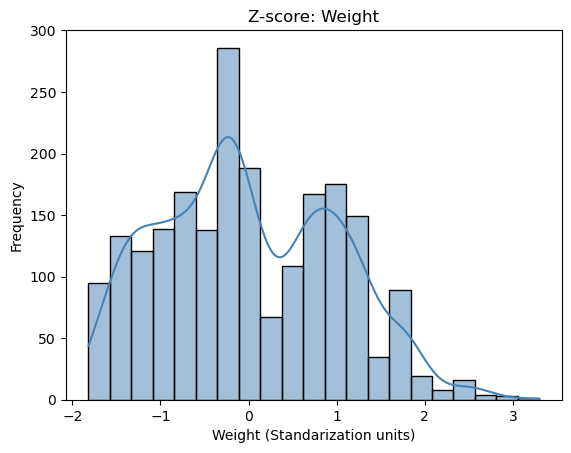

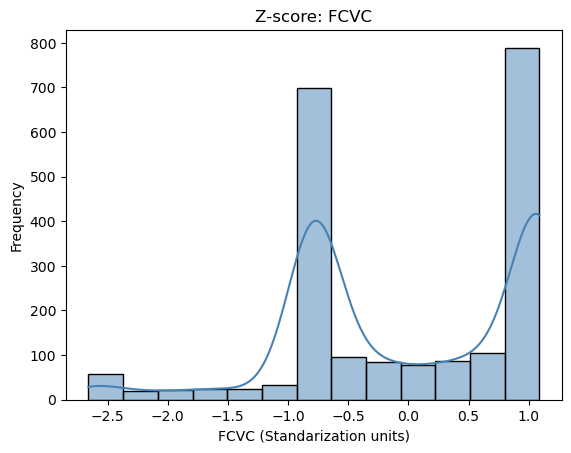

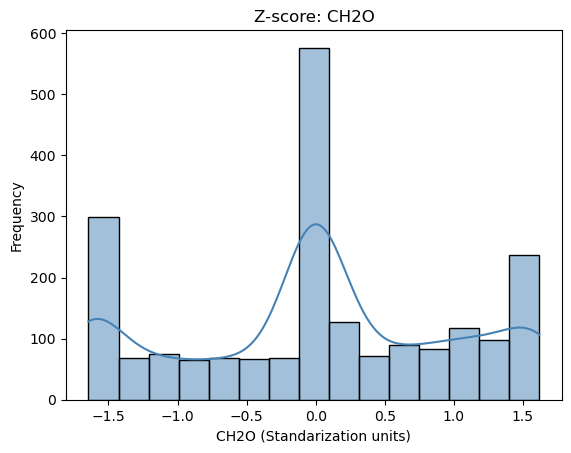

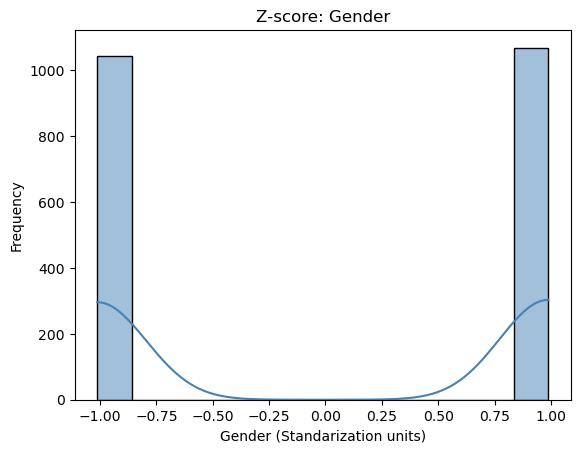

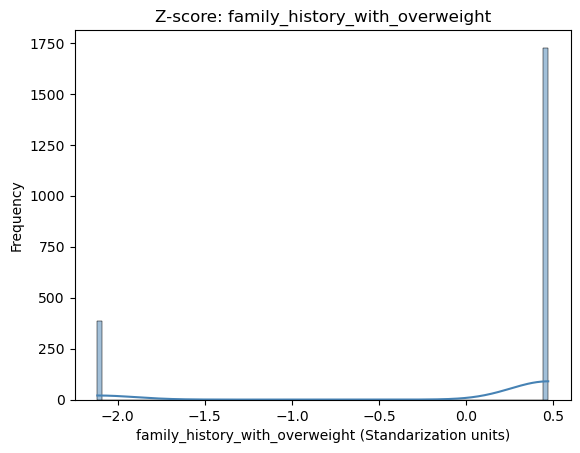

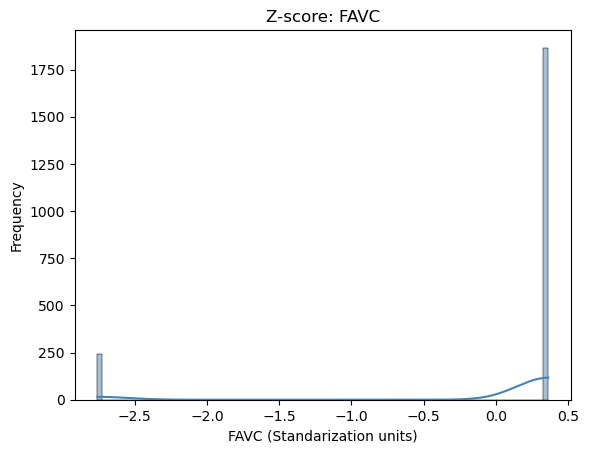

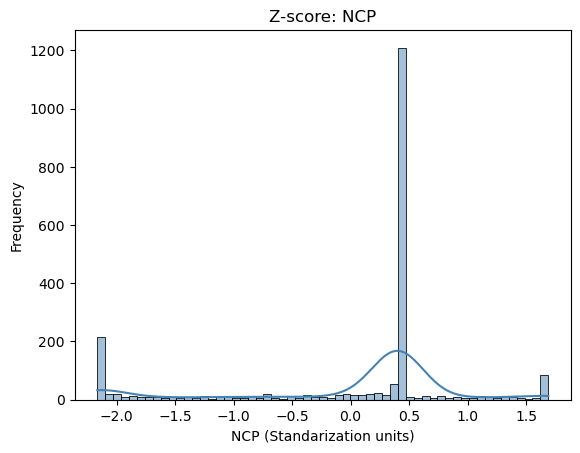

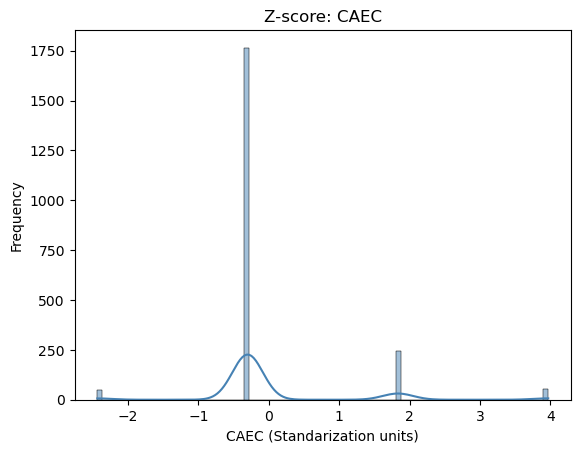

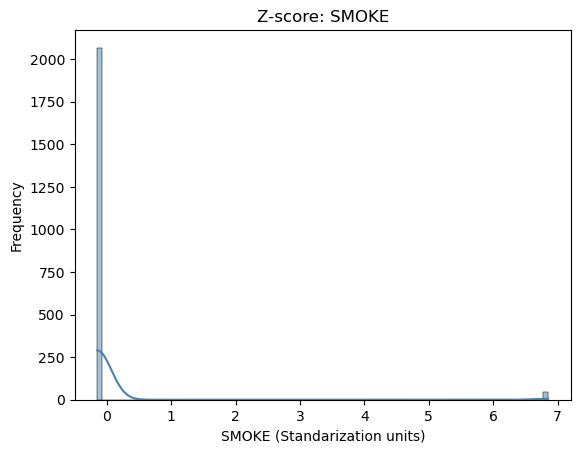

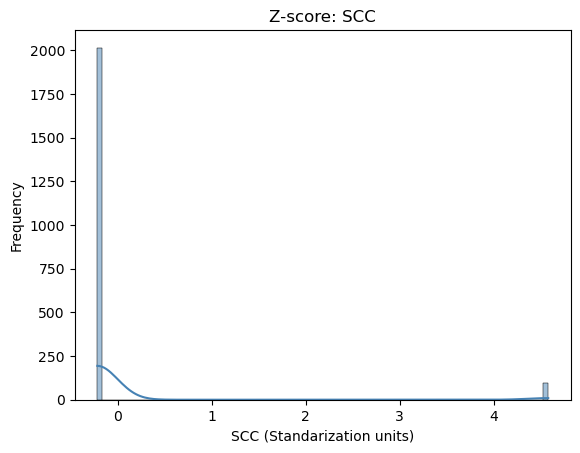

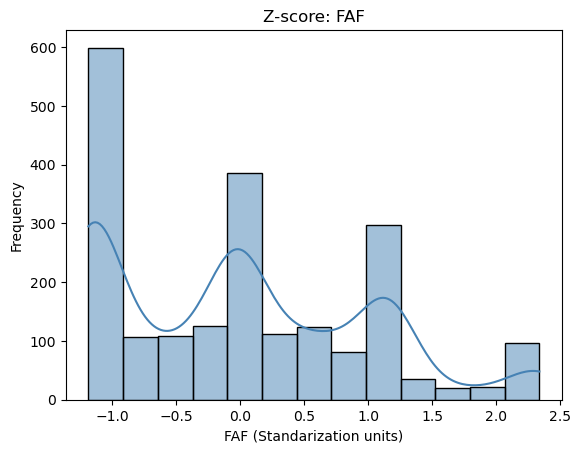

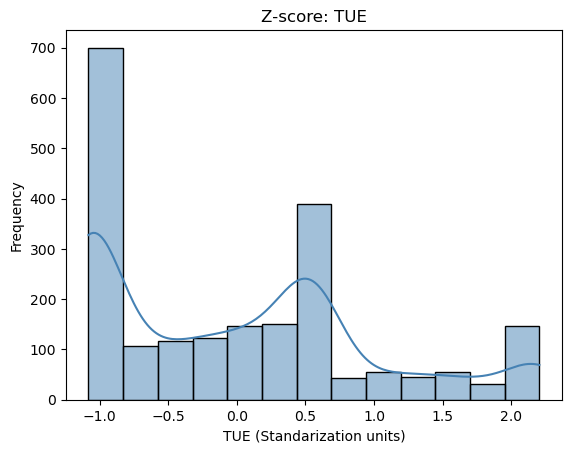

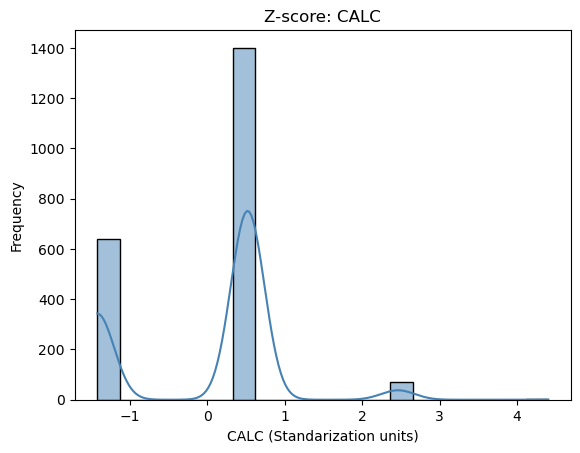

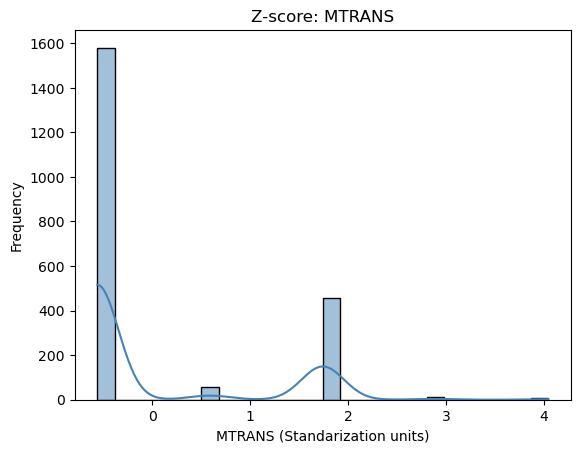

In [45]:
columns_zscore = ['Age', 'Height', 'Weight', 'FCVC', 'CH2O', 'Gender', 'family_history_with_overweight', 'FAVC', 'NCP', 'CAEC', 'SMOKE',
                  'SCC', 'FAF', 'TUE', 'CALC', 'MTRANS']

scaler = StandardScaler()
df[columns_zscore] = scaler.fit_transform(df[columns_zscore])

for col in columns_zscore:
    plt.figure
    sns.histplot(df[col], kde=True, color="steelblue")
    plt.title(f"Z-score: {col}")
    plt.xlabel(f"{col} (Standarization units)")
    plt.ylabel("Frequency")
    plt.show()

# Supervised Learning

In [55]:
# Store the column 'NObeyesdad' in 'label'
label = df[['NObeyesdad']]

# Display first 5 records
label.head()

,NObeyesdad
0,1
1,1
2,1
3,2
4,3


In [57]:
# Drop the label column (Last)
df_1 = df.drop(['NObeyesdad'], axis = 1)

# axis = 1 means along columnwise

In [59]:
# Display last 5 records
df_1.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS
0,-1.011914,-0.522124,-0.875589,-0.862558,0.472291,-2.759769,-0.785019,0.404153,-0.300346,-0.145900,-0.013073,-0.218272,-1.188039,0.561997,-1.419172,-0.562491
1,-1.011914,-0.522124,-1.947599,-1.168077,0.472291,-2.759769,1.088342,0.404153,-0.300346,6.853997,1.618759,4.581439,2.339750,-1.080625,0.521160,-0.562491
2,0.988227,-0.206889,1.054029,-0.366090,0.472291,-2.759769,-0.785019,0.404153,-0.300346,-0.145900,-0.013073,-0.218272,1.163820,0.561997,2.461491,-0.562491
3,0.988227,0.423582,1.054029,0.015808,-2.117337,-2.759769,1.088342,0.404153,-0.300346,-0.145900,-0.013073,-0.218272,1.163820,-1.080625,2.461491,0.589225
4,0.988227,-0.364507,0.839627,0.122740,-2.117337,-2.759769,-0.785019,-2.167023,-0.300346,-0.145900,-0.013073,-0.218272,-1.188039,-1.080625,0.521160,-0.562491


In [61]:
# Store the values as X and y before applying the ML model
# For a machine learning model, we need to split the data into independent and dependent variables

X = df_1           # Features (independent variables) from the ObesityDataSet

y = label            # Target variable (NObeyesdad) for the prediction

# Regarding the dataset

In [63]:
# Display the label variables of binary types
y.value_counts()

NObeyesdad
4             351
6             324
5             297
2             290
3             290
1             287
0             272
Name: count, dtype: int64

In [66]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 42) # 80% training and 20% test
# Controls the shuffling applied to the data before applying the split.

In [68]:
# Display the rows and columns (dimenions) of an unsplitted dataset
print('Total number of rows and columns for the complete dataset: ', X.shape, y.shape)

# Display the rows and columns (dimenions) of the splitted dataset
print('Number of rows and columns after splitting dataset: ', X_train.shape, X_test.shape, y_train.shape, y_test.shape )

Total number of rows and columns for the complete dataset:  (2111, 16) (2111, 1)
Number of rows and columns after splitting dataset:  (1688, 16) (423, 16) (1688, 1) (423, 1)


# SVM

In [71]:
# Create a classifier
cls_svm = svm.SVC(kernel = "linear")    # Press shift + tab key simultaneoulsy to get the help for the function or method SVC

# Train the model
cls_svm.fit(X_train, y_train)

# Predict the response
y_pred = cls_svm.predict(X_test)

In [73]:
# accuracy
print("accuracy:", metrics.accuracy_score(y_test, y_pred))

# precision score
print("precision:", metrics.precision_score(y_test, y_pred))

# recall score
print("recall" , metrics.recall_score(y_test, y_pred))

# Display upto 2 decimal places
print( "accuracy: {:.2f}".format(metrics.accuracy_score(y_test, y_pred)) )
print( "precision: {:.2f}".format(metrics.precision_score(y_test, y_pred)) )
print( "recall: {:.2f}".format(metrics.recall_score(y_test, y_pred)) )

accuracy: 0.9598108747044918


ValueError: Target is multiclass but average='binary'. Please choose another average setting, one of [None, 'micro', 'macro', 'weighted'].

In [75]:
# Display the unique classes present in y_test and their counts
unique_classes, class_counts = np.unique(y_test, return_counts=True)

for cls, count in zip(unique_classes, class_counts):
    print(f"Class {cls}: Count = {count}")

Class 0: Count = 56
Class 1: Count = 62
Class 2: Count = 56
Class 3: Count = 50
Class 4: Count = 78
Class 5: Count = 58
Class 6: Count = 63


In [79]:
# Display the unique classes present in y_test and their counts
unique_classes, class_counts = np.unique(y_pred, return_counts=True)

for cls, count in zip(unique_classes, class_counts):
    print(f"Class {cls}: Count = {count}")

Class 0: Count = 62
Class 1: Count = 54
Class 2: Count = 59
Class 3: Count = 50
Class 4: Count = 76
Class 5: Count = 59
Class 6: Count = 63


<Axes: >

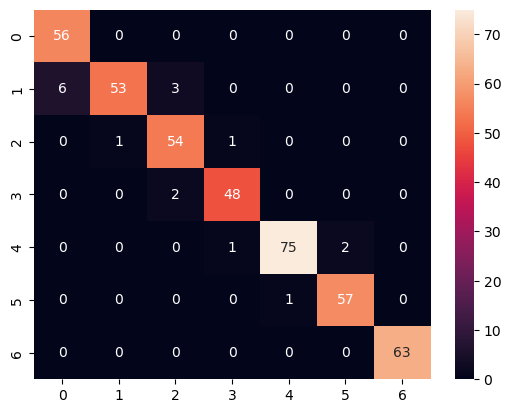

In [81]:
# Call a method predict by using an object classifier 'cls_svm'
y_predict = cls_svm.predict(X_test)

# Calculate cm by calling a method named as 'confusion_matrix'
cm = confusion_matrix(y_test, y_predict)

# Call a method heatmap() to plot confusion matrix
sns.heatmap(cm, annot = True)

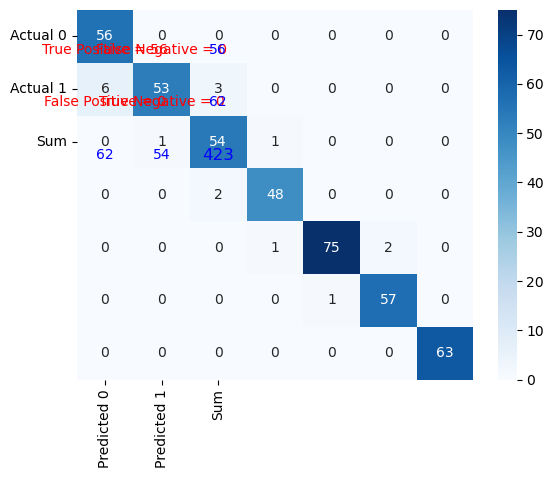

In [83]:
# Call a method predict by using an object classifier 'cls_svm'
y_predict = cls_svm.predict(X_test)

# Calculate cm by calling a method named as 'confusion_matrix'
cm = confusion_matrix(y_test, y_predict)

# Define labels for the confusion matrix
labels = ['True Positive', 'False Negative', 'False Positive', 'True Negative']

# Create a heatmap with annotations and sum of rows/columns
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Predicted 0', 'Predicted 1', 'Sum'], yticklabels=['Actual 0', 'Actual 1', 'Sum'])

# Add labels for TP, FP, TN, FN
for i in range(len(labels)):
    plt.text(i % 2 + 0.5, int(i / 2) + 0.75, str(labels[i]) + " = " + str(cm.flatten()[i]), color='red', fontsize=10, ha='center', va='center')

# Add sum of rows and columns
for i in range(2):
    plt.text(2.5, i + 0.75, str(cm.sum(axis=1)[i]), color='blue', fontsize=10, ha='center', va='center')
    plt.text(i + 0.5, 2.75, str(cm.sum(axis=0)[i]), color='blue', fontsize=10, ha='center', va='center')

# Add overall sum
plt.text(2.5, 2.75, str(cm.sum()), color='blue', fontsize=12, ha='center', va='center')

# Show the plot
plt.show()